# Description clusters vs. price — PCA → KMeans → hedonic premium

Covers two of the three ideas on the list:

**(2) PCA as a step *before* clustering, not the end product.** Reduce the 384-d
description embeddings to 100 PCs, cluster there, then project to 2D and colour the
scatter by cluster and by price per m². The 2D projection is for *looking*, never
for fitting — clustering happens in the 100-d space.

**(3) The money chart.** Cluster membership vs. price, controlling for the structural
features (size, rooms, property type, location, platform, agency). "Listings whose
descriptions emphasise X rent for Y% more, even after controlling for size and
location."

Idea (1) — pulling the listings closest to each centroid and having an LLM name the
themes — is deliberately *not* done here. Clusters are named from distinguishing
TF-IDF terms only, which is enough to make the charts readable.

Everything readable is also dumped to **`cluster_report.txt`** next to this notebook
(§5.1), so the cluster profiles and the premium tables can be read outside Jupyter.

---

## Data provenance and what it does *not* cover

Everything comes from the caches yesterday's run left in `analysis/cache/`. Nothing
here hits Supabase, so every number below is reproducible from disk.

| file | what it gives us |
|---|---|
| `listings_since_2026-08-01.csv` | 19,371 rows, structural + normalised fields (`price_eur`, `area_sqm`, `rooms_norm`, `sector`, `is_agency`, `price_per_sqm`) |
| `fees_parsed.csv` | 10,000 rows carrying the **raw `description`** — the only place the text survives |

`analysis/fetch_cache.py::normalise` drops `description` before caching ("~10x the
size of every other column combined"), so the text has to come from the fees cache.
That join is what bounds this analysis, and it bounds it in three ways worth stating
up front rather than discovering later:

1. **Sample, not census — 7,950 rows, not 19,371.** The intersection of the two
   caches is 8,298 rows, and the price/area guards below take it to 7,950.
2. **`fees.py::fetch` is not a random sample.** It keyset-pages `url > last` and
   stops at 10,000, so it takes the first 10k rows *in URL order* — i.e. skewed by
   platform domain. Imobiliare.ro is 299 rows in the fees cache and 0 in the
   listings cache; the merged frame is storia 71% / olx 29%.
3. **Live listings only.** `fees.py` filters `is_available = 1`, so delisted rows are
   absent. No turnover or time-on-market question can be asked of this frame.

These are rentals (median €580/mo, median €10.7/m²/mo), Bucharest / Cluj-Napoca / Iași,
first seen since 2026-08-01.

In [111]:
import html
import os
import re
import unicodedata

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
SRC_CACHE = os.path.join(ROOT, "analysis", "cache")
CACHE = os.path.join(ROOT, "ad hoc analysis", "cache")   # embeddings etc. land here
REPORT = os.path.join(ROOT, "ad hoc analysis", "cluster_report.txt")
os.makedirs(CACHE, exist_ok=True)

SEED = 0
N_PCS = 100       # dimensionality for clustering — 91% of variance
K = 6             # cluster count — justified in the sweep below

# Chart defaults. The legend settings are the point: a 6-way categorical legend at
# full size eats a quarter of a scatter, so labels go small, below the axes, and the
# long cluster names live in CLUSTER_LABELS / cluster_report.txt instead.
mpl.rcParams.update({
    "figure.dpi": 110,
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.fontsize": 7,
    "legend.title_fontsize": 7,
    "legend.frameon": False,
    "legend.handletextpad": 0.3,
    "legend.columnspacing": 1.0,
    "legend.labelspacing": 0.3,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
})

pd.set_option("display.width", 140)
print(ROOT)

/Users/alexandrus.home/Projects/Startup/Real-estate-parser


## 1. Build the frame

Guards, and why each one is here:

* `area_sqm` 15–400 m² and `price_eur` 100–5,000 — the raw cache has an
  `area_sqm` max of 64,600 and a `price_eur` max of 399,000, i.e. sale prices and
  unit errors that leaked into a rental pull.
* `price_per_sqm` 3–40 €/m²/mo, applied at modelling time (27 rows) — the ratio
  catches pairs that pass both individual guards but cannot both be right.

The guards are stated as explicit ranges rather than quantile-trimmed, because
quantile trimming would silently remove a real luxury tail along with the errors.

In [112]:
listings = pd.read_csv(os.path.join(SRC_CACHE, "listings_since_2026-08-01.csv"))
fees = pd.read_csv(os.path.join(SRC_CACHE, "fees_parsed.csv"), usecols=["url", "description"])

df = listings.merge(fees, on="url", how="inner")
print(f"merged on url            : {len(df):,}")

df = df[df.price_eur.notna() & df.area_sqm.notna() & df.description.notna()]
df = df[df.area_sqm.between(15, 400) & df.price_eur.between(100, 5000)]
df["price_per_sqm"] = df.price_eur / df.area_sqm
df = df.reset_index(drop=True)

print(f"after price/area guards  : {len(df):,}")
print(df[["price_eur", "area_sqm", "price_per_sqm"]].describe().round(1).T)
print("\nplatform:", df.platform_id.value_counts().to_dict())
print("city    :", df.city.value_counts().to_dict())

merged on url            : 8,298
after price/area guards  : 7,950
                count   mean    std    min    25%    50%    75%     max
price_eur      7950.0  720.1  446.6  100.0  500.0  600.0  799.0  5000.0
area_sqm       7950.0   62.6   23.3   15.0   50.0   58.0   70.0   300.0
price_per_sqm  7950.0   11.5    4.8    0.8    9.0   10.7   12.9   264.7

platform: {'storia': 5862, 'olx': 2088}
city    : {'Bucuresti': 5718, 'Cluj-Napoca': 1320, 'Iasi': 912}


## 2. Embed the descriptions

`paraphrase-multilingual-MiniLM-L12-v2` — the same 384-d model the production
pipeline uses (`embedding.py`, `embedding-service/embed_job.py`), so anything that
looks useful here transfers to the live `listings.embedding` column without
re-embedding the corpus under a different model.

Embeddings are L2-normalised at encode time, which makes Euclidean distance in the
PCA space monotone in cosine distance — KMeans is then clustering on angle, which is
the metric these embeddings are trained for.

Cached to `ad hoc analysis/cache/desc_emb.npy` (~12 MB); the encode takes ~25s on CPU.
Descriptions are truncated at 2,000 characters — the model's own window is 128
tokens anyway, so this only saves tokenizer work.

In [113]:
EMB_PATH = os.path.join(CACHE, "desc_emb.npy")

if os.path.exists(EMB_PATH):
    E = np.load(EMB_PATH)
    assert len(E) == len(df), "cache is stale — delete desc_emb.npy and re-run"
    print("loaded from cache")
else:
    from sentence_transformers import SentenceTransformer

    model = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")
    E = model.encode(
        df.description.str.slice(0, 2000).tolist(),
        batch_size=64,
        show_progress_bar=True,
        normalize_embeddings=True,
    ).astype(np.float32)
    np.save(EMB_PATH, E)

print(E.shape)

loaded from cache
(7950, 384)


## 3. PCA — the step *before* clustering

100 PCs keep **91%** of the variance. Clustering there rather than in the raw 384-d
space is the defensible move: it strips the low-variance directions that are mostly
encoder noise, and it makes KMeans' distance computation behave (in 384 d the
distances concentrate and the centroids stop separating).

Note the number in the second line — **the first two PCs carry only 18%**. That is the
whole argument for not treating a PCA-2D scatter as the analysis. It is a picture of
a fifth of the signal.

At 100 PCs the partition is the same one 50 PCs found — the six clusters below are
identical in size and content, only renumbered. The extra 14 points of variance are
spread across directions too thin to move a centroid, which is itself reassuring: the
result is not an artefact of where the PCA cut-off was put.

In [114]:
pca = PCA(n_components=N_PCS, random_state=SEED).fit(E)
Z = pca.transform(E)

print(f"variance explained, {N_PCS} PCs : {pca.explained_variance_ratio_.sum():.1%}")
print(f"variance explained, first 2 PCs: {pca.explained_variance_ratio_[:2].sum():.1%}")

variance explained, 100 PCs : 91.3%
variance explained, first 2 PCs: 18.0%


## 4. Choosing k

Silhouette across k = 3…10. Read the absolute values with suspicion: on sentence
embeddings a silhouette of 0.07–0.12 is normal and does **not** mean "no structure" —
the embedding space is dense and near-uniformly distributed, so no partition scores
well. Inertia has no elbow either.

**On the metric's direction:** silhouette runs −1 → +1 and *higher is better*
(+1 = tight, well-separated clusters; 0 = points sit on a boundary). k = 6 scores
**0.074, the lowest** of the sweep, so it is chosen *despite* the metric, not because
of it — on legibility: it is the smallest k whose clusters each have a readable,
distinct term profile (§5). k = 3 scores highest but collapses everything into one
5,198-row blob that says nothing.

That is a defensible call on this kind of data, but it is a judgement call, and it is
the one to re-check first if the premium in §8 ever needs defending: re-run §8 at
k = 5 and k = 8 and confirm the sign and rough size hold.

Note the ~297-row cluster that survives every k — that is a single agency's
boilerplate, and §5 identifies it.

In [115]:
sweep = []
for k in range(3, 11):
    km_k = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)
    sil = silhouette_score(Z, km_k.labels_, sample_size=4000, random_state=SEED)
    sweep.append({"k": k, "silhouette": sil, "inertia": km_k.inertia_,
                  "sizes": np.bincount(km_k.labels_)})
    print(f"k={k:2d}  silhouette={sil:.4f}  inertia={km_k.inertia_:7.0f}  sizes={sweep[-1]['sizes']}")

k= 3  silhouette=0.1153  inertia=   2349  sizes=[ 306 2446 5198]
k= 4  silhouette=0.0884  inertia=   2261  sizes=[4474  297 1185 1994]
k= 5  silhouette=0.0902  inertia=   2182  sizes=[ 626 1260 1247 4520  297]
k= 6  silhouette=0.0739  inertia=   2122  sizes=[ 297 2758 1084 1124 2135  552]
k= 7  silhouette=0.0804  inertia=   2076  sizes=[2856  297 1702  765  184 1048 1098]
k= 8  silhouette=0.0776  inertia=   2037  sizes=[ 858  986 1425  296 1526  182 2031  646]
k= 9  silhouette=0.0765  inertia=   2009  sizes=[1078  968  688 1330 1797 1034  578  182  295]
k=10  silhouette=0.0769  inertia=   1983  sizes=[ 519  937 1638  295  837  688 1188 1013  653  182]


In [116]:
km = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(Z)
df["cluster"] = km.labels_.astype(str)

# Distance to own centroid — the handle for idea (1), if it gets picked up later:
# df.nsmallest(10, "centroid_dist") within a cluster gives its most representative ads.
df["centroid_dist"] = np.linalg.norm(Z - km.cluster_centers_[km.labels_], axis=1)

print(df.cluster.value_counts().sort_index())

cluster
0     297
1    2758
2    1084
3    1124
4    2135
5     552
Name: count, dtype: int64


## 5. What each cluster actually is

Distinguishing terms, not merely frequent ones: mean TF-IDF *inside* the cluster minus
mean TF-IDF outside it. Ranking on raw frequency would return "apartament", "camere",
"mobilat" for all six.

In [117]:
def strip_diacritics(text: str) -> str:
    text = html.unescape(str(text))
    text = unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode()
    return re.sub(r"\s+", " ", text).lower()


# Romanian has no stop-word list in sklearn; this is the same normalise-then-match
# approach analysis/fees.py takes, and the same reason: descriptions carry raw HTML
# entities (&#539;) and both "garanție" and "garantie" occur.
RO_STOP = ("de la si in cu pe un o al ale ai a e este sunt pentru din se ce care are "
           "au fi mai foarte ca nu prin sau lui ei intr intre dar dupa fara catre va "
           "te ne").split()

corpus = df.description.map(strip_diacritics)
tfidf = TfidfVectorizer(max_features=20_000, ngram_range=(1, 2), min_df=10, stop_words=RO_STOP)
X_tfidf = tfidf.fit_transform(corpus)
vocab = np.array(tfidf.get_feature_names_out())


def top_terms(cluster: str, n: int = 14) -> list[str]:
    """Terms that separate this cluster from the rest, by TF-IDF lift."""
    mask = (df.cluster == cluster).values
    inside = np.asarray(X_tfidf[mask].mean(axis=0)).ravel()
    outside = np.asarray(X_tfidf[~mask].mean(axis=0)).ravel()
    return list(vocab[np.argsort(-(inside - outside))[:n]])


for c in sorted(df.cluster.unique()):
    sub = df[df.cluster == c]
    print(f"\n─── cluster {c}   n={len(sub):,}   "
          f"rent_med=€{sub.price_eur.median():.0f}   area_med={sub.area_sqm.median():.0f} m²   "
          f"€/m²_med={sub.price_per_sqm.median():.1f}")
    print("   terms :", ", ".join(top_terms(c)))
    print("   city  :", sub.city.value_counts(normalize=True).round(2).to_dict())
    print("   plat  :", sub.platform_id.value_counts(normalize=True).round(2).to_dict())
    print("   rooms :", sub.rooms_norm.value_counts(normalize=True).round(2).to_dict())
    print("   agency:", sub.is_agency.value_counts(normalize=True, dropna=False).round(2).to_dict())


─── cluster 0   n=297   rent_med=€600   area_med=60 m²   €/m²_med=10.2
   terms : imobiliara, bucuresti, apex, apex imobiliare, imobiliara bucuresti, imobiliare romania, agentie imobiliara, romania, contor, romania agentie, proximitatea fata, identitate, agentie, proximitatea
   city  : {'Bucuresti': 1.0, 'Iasi': 0.0}
   plat  : {'storia': 0.97, 'olx': 0.03}
   rooms : {'2': 0.66, '3': 0.25, '4': 0.05, '1': 0.04, '?': 0.0}
   agency: {True: 0.97, nan: 0.03}

─── cluster 1   n=2,758   rent_med=€580   area_med=55 m²   €/m²_med=10.6
   terms : ace imobiliare, ace, apartament camere, camere, mobilat utilat, apartament, utilat, luna chirie, inchiriere apartament, apartamentul, camere situat, luna, alte, comisionul
   city  : {'Bucuresti': 0.68, 'Cluj-Napoca': 0.18, 'Iasi': 0.15}
   plat  : {'storia': 0.79, 'olx': 0.21}
   rooms : {'2': 0.91, '?': 0.03, '3': 0.03, '1': 0.02, '4': 0.0, '5+': 0.0}
   agency: {True: 0.76, nan: 0.21, False: 0.02}

─── cluster 2   n=1,084   rent_med=€755   area_

### Labels

Read straight off the term lists above. Two versions on purpose: the long one is what
goes in the text report, the short one is what goes in chart legends — a 6-way legend
carrying the long names eats a quarter of every scatter.

**Re-derive both if the seed, k, or `N_PCS` changes.** The integer labels are not
stable: moving from 50 to 100 PCs kept all six clusters intact but renumbered every
one of them.

In [118]:
CLUSTER_LABELS = {
    "0": "one agency's template (APEX, Bucharest only)",
    "1": "2-room agency listing (portal boilerplate)",
    "2": "premium-segment vocabulary ('premium', 'lux', 'finisaje')",  # renamed in §9
    "3": "private landlord, garsoniera / metro-proximity",
    "4": "room-by-room descriptive (3-room, two baths, living)",
    "5": "structured agency template (amenities checklist, cod anunt)",
}
CLUSTER_SHORT = {
    "0": "APEX template",
    "1": "2-room boilerplate",
    "2": "premium-segment",
    "3": "private / garsoniera",
    "4": "room-by-room",
    "5": "agency checklist",
}
assert set(CLUSTER_LABELS) == set(df.cluster.unique()), "labels are stale — re-read §5"

df["cluster_label"] = df.cluster.map(CLUSTER_LABELS)
df["cluster_short"] = df.cluster.map(CLUSTER_SHORT)
df.cluster_short.value_counts()

cluster_short
2-room boilerplate      2758
room-by-room            2135
private / garsoniera    1124
premium-segment         1084
agency checklist         552
APEX template            297
Name: count, dtype: int64

### 5.1 Dump the cluster results to `cluster_report.txt`

Same content as §5 plus the composition breakdowns and three representative ads per
cluster (the ones nearest the centroid), written to a plain text file next to the
notebook so it can be read, diffed and pasted without a Jupyter kernel.

The premium tables from §8 are appended to the same file at the end of the run.

In [119]:
def write_cluster_report(frame: pd.DataFrame, path: str = REPORT) -> str:
    lines = [
        "=" * 78,
        "DESCRIPTION CLUSTERS — rental listings, first_seen_at >= 2026-08-01",
        "=" * 78,
        "",
        f"rows            : {len(frame):,}  (of 19,371 in the listings cache — see provenance)",
        f"embedding       : paraphrase-multilingual-MiniLM-L12-v2, 384-d, L2-normalised",
        f"reduction       : PCA {N_PCS} components ({pca.explained_variance_ratio_.sum():.1%} of variance)",
        f"clustering      : KMeans k={K}, n_init=10, random_state={SEED}",
        f"cities          : {frame.city.value_counts().to_dict()}",
        f"platforms       : {frame.platform_id.value_counts().to_dict()}",
        "",
        "Cluster numbers are NOT stable across re-runs — they change with the seed, k",
        "and N_PCS. Labels below were read off the term lists in this run.",
        "",
    ]

    for c in sorted(frame.cluster.unique()):
        sub = frame[frame.cluster == c]
        lines += [
            "-" * 78,
            f"CLUSTER {c} — {CLUSTER_LABELS[c]}",
            "-" * 78,
            f"  listings      : {len(sub):,}  ({len(sub) / len(frame):.1%} of the frame)",
            f"  median rent   : EUR {sub.price_eur.median():,.0f}/month",
            f"  median area   : {sub.area_sqm.median():.0f} m2",
            f"  median EUR/m2 : {sub.price_per_sqm.median():.1f}",
            "",
            "  distinguishing terms (TF-IDF lift vs. the rest of the corpus):",
            "    " + ", ".join(top_terms(c)),
            "",
            f"  city    : {sub.city.value_counts(normalize=True).round(2).to_dict()}",
            f"  platform: {sub.platform_id.value_counts(normalize=True).round(2).to_dict()}",
            f"  rooms   : {sub.rooms_norm.value_counts(normalize=True).round(2).to_dict()}",
            f"  agency  : {sub.is_agency.value_counts(normalize=True, dropna=False).round(2).to_dict()}",
            "",
            "  closest to centroid (most representative ads):",
        ]
        for _, row in sub.nsmallest(3, "centroid_dist").iterrows():
            excerpt = re.sub(r"\s+", " ", strip_diacritics(row.description))[:300]
            lines += [f"    - [{row.rooms_norm}r  {row.area_sqm:.0f}m2  EUR{row.price_eur:,.0f}]  {excerpt}…", ""]
        lines.append("")

    with open(path, "w") as fh:
        fh.write("\n".join(lines))
    return path


print("wrote", write_cluster_report(df))

wrote /Users/alexandrus.home/Projects/Startup/Real-estate-parser/ad hoc analysis/cluster_report.txt


## 6. The 2D map

Two projections, because they answer different questions:

* **PCA-2D** — honest but blunt (18% of variance). Use it to check that the clusters
  are not an artefact of the projection.
* **t-SNE on the 100 PCs** — separates the clusters far more cleanly and is the one
  worth putting in a post. UMAP would usually be the better tool here; it is not
  installed in this venv, and t-SNE-on-PCA is the standard substitute. Its axes carry
  **no** meaning and distances between well-separated blobs are not interpretable.

Each is drawn twice — coloured by cluster, and coloured by price per m² — because the
one-image claim is that the two colourings line up.

Matplotlib rather than Plotly: these are static charts for a post, and the Plotly
versions were throwing renderer errors in this kernel. Legends sit *below* the axes at
7 pt in three columns, so they cost no plot area; the full cluster names are in
`cluster_report.txt`.

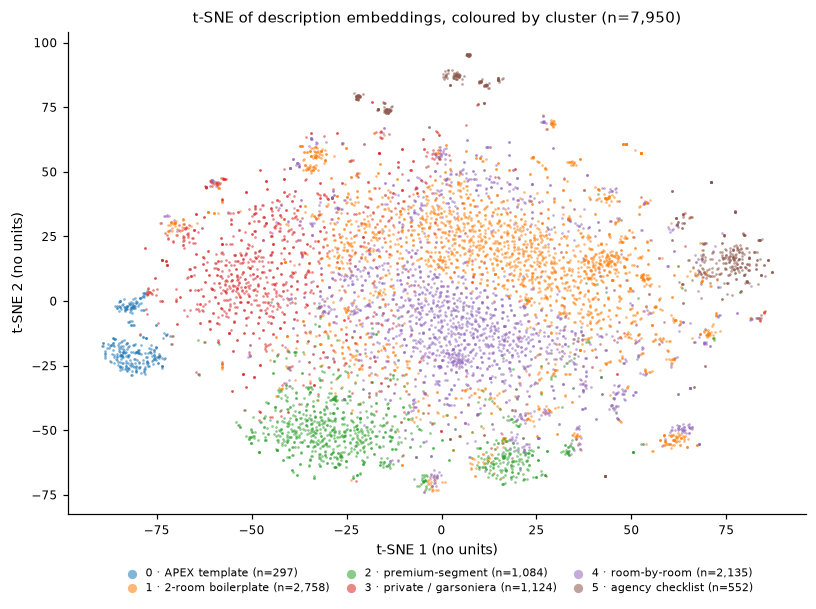

In [120]:
P2 = Z[:, :2]

TSNE_PATH = os.path.join(CACHE, f"tsne2d_{N_PCS}pcs.npy")
if os.path.exists(TSNE_PATH):
    T2 = np.load(TSNE_PATH)
    assert len(T2) == len(df), "cache is stale — delete the tsne2d_*.npy files and re-run"
else:
    T2 = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(Z)
    np.save(TSNE_PATH, T2)   # ~10s

# One fixed colour per cluster, shared by every chart below so the eye can carry a
# cluster from one figure to the next.
PALETTE = dict(zip(sorted(df.cluster.unique()), plt.get_cmap("tab10").colors))


def scatter_by_cluster(xy: np.ndarray, title: str, xlabel: str, ylabel: str) -> None:
    fig, ax = plt.subplots(figsize=(7.5, 5.6))
    for c in sorted(df.cluster.unique()):
        m = (df.cluster == c).values
        ax.scatter(xy[m, 0], xy[m, 1], s=3, alpha=0.55, linewidths=0,
                   color=PALETTE[c], label=f"{c} · {CLUSTER_SHORT[c]} (n={m.sum():,})")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    # markerscale lifts the 3 pt dots to something visible without enlarging the text
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=3, markerscale=3.5)
    fig.tight_layout()
    plt.show()


scatter_by_cluster(T2, f"t-SNE of description embeddings, coloured by cluster (n={len(df):,})",
                   "t-SNE 1 (no units)", "t-SNE 2 (no units)")

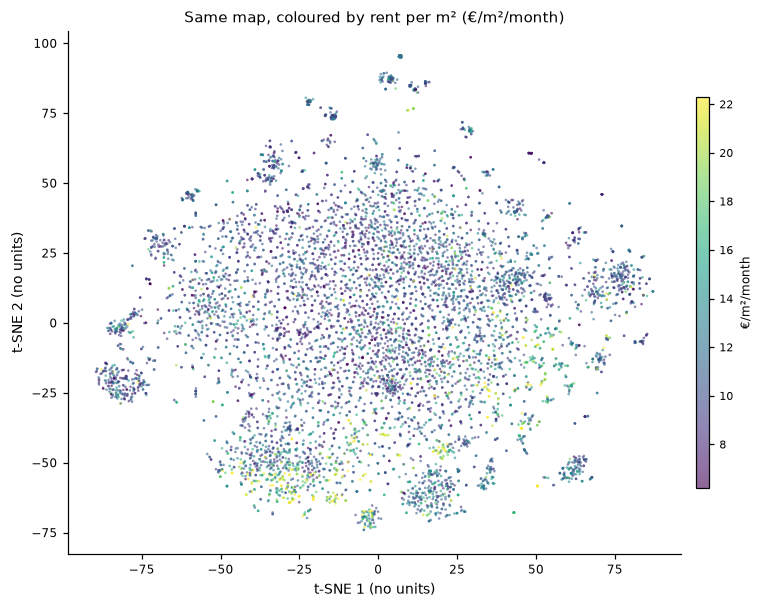

In [121]:
# Colour scale winsorised at the 2nd/98th percentile: one €40/m² outlier otherwise
# flattens the ramp so every point reads as the same shade.
lo_c, hi_c = df.price_per_sqm.quantile([0.02, 0.98])

fig, ax = plt.subplots(figsize=(7.5, 5.6))
sc = ax.scatter(T2[:, 0], T2[:, 1], c=df.price_per_sqm.clip(lo_c, hi_c),
                s=3, alpha=0.6, linewidths=0, cmap="viridis")
ax.set_title("Same map, coloured by rent per m² (€/m²/month)")
ax.set_xlabel("t-SNE 1 (no units)")
ax.set_ylabel("t-SNE 2 (no units)")
# shrink+aspect keep the colourbar a slim strip rather than a full-height block
cbar = fig.colorbar(sc, ax=ax, shrink=0.75, aspect=30, pad=0.02)
cbar.set_label("€/m²/month", fontsize=8)
cbar.ax.tick_params(labelsize=7)
fig.tight_layout()
plt.show()

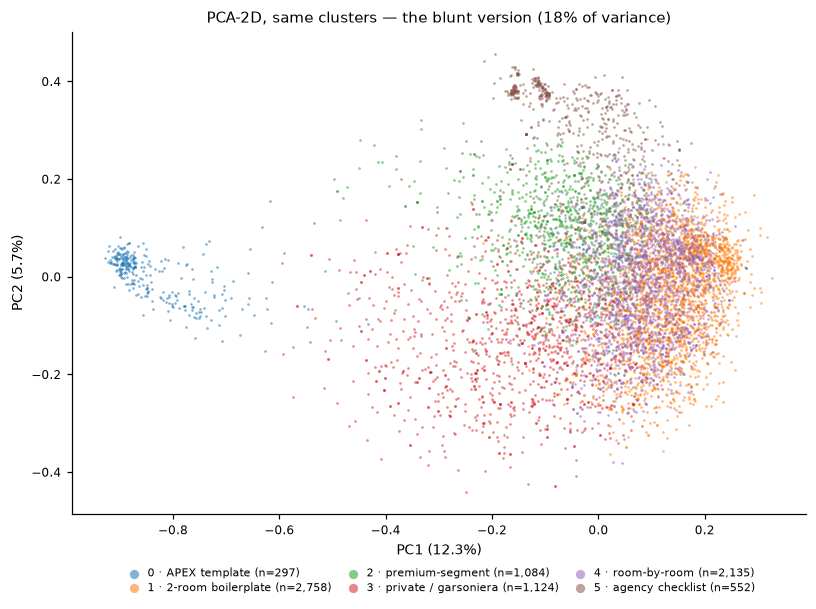

In [122]:
scatter_by_cluster(P2, "PCA-2D, same clusters — the blunt version (18% of variance)",
                   f"PC1 ({pca.explained_variance_ratio_[0]:.1%})",
                   f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")

## 7. Diagnostic: do these clusters just re-encode structure?

This has to run **before** any price claim, and it is the finding that changes how the
rest is read. The crosstabs below show the clusters are not "themes" in the way the
original framing hoped. They largely track:

* **room count** — cluster 1 is 91% 2-room, cluster 4 is 63% 3-room;
* **who wrote the ad** — cluster 0 is 97% agency and is one firm's template; cluster 3
  is 70% OLX and mostly private landlords.

Which is exactly what raw embeddings of portal copy *should* do: agency boilerplate is
the most repeated text in the corpus, so it dominates the variance. Two consequences:

1. Nothing here can be reported as "descriptions emphasising X" without the controls in
   §8 — the uncontrolled gaps are mostly room count wearing a text disguise.
2. If the goal is genuinely thematic clusters, the next iteration should strip the
   boilerplate first (drop near-duplicate sentences shared across an agency's ads, or
   embed only the non-templated remainder) and re-cluster. That is a separate run.

In [123]:
for col in ("rooms_norm", "platform_id", "is_agency", "city"):
    print(f"\n=== cluster × {col} (row %) ===")
    print((pd.crosstab(df.cluster_short, df[col].fillna("unknown"), normalize="index") * 100).round(0))


=== cluster × rooms_norm (row %) ===
rooms_norm               1     2     3     4   5+     ?
cluster_short                                          
2-room boilerplate     2.0  91.0   3.0   0.0  0.0   3.0
APEX template          4.0  66.0  25.0   5.0  0.0   0.0
agency checklist       3.0  68.0  23.0   4.0  1.0   1.0
premium-segment        4.0  55.0  27.0   8.0  2.0   4.0
private / garsoniera  39.0  37.0  10.0   2.0  0.0  13.0
room-by-room           6.0  14.0  63.0  10.0  1.0   6.0

=== cluster × platform_id (row %) ===
platform_id            olx  storia
cluster_short                     
2-room boilerplate    21.0    79.0
APEX template          3.0    97.0
agency checklist       5.0    95.0
premium-segment       16.0    84.0
private / garsoniera  70.0    30.0
room-by-room          24.0    76.0

=== cluster × is_agency (row %) ===
is_agency             False  True  unknown
cluster_short                             
2-room boilerplate      2.0  76.0     21.0
APEX template           0.0  

## 8. The money chart — cluster premium, controlled

Hedonic log-price regression:

$$\log(\text{rent}) = \beta_0 + \beta_1 \log(\text{area}) + \gamma\,\text{rooms} + \delta\,\text{type} + \theta\,\text{location} + \phi\,\text{platform} + \psi\,\text{agency} + \sum_c \pi_c \mathbb{1}[\text{cluster}=c] + \varepsilon$$

with $\exp(\pi_c) - 1$ read as the % rent premium of cluster $c$ over the baseline
(the largest cluster), holding the structural features fixed.

Two implementation notes:

* **Log-price, not price per m².** Regressing €/m² on log-area would put area on both
  sides of the equation. Log-price with `log_area` as a regressor lets the data
  estimate the size elasticity instead of imposing 1.0 — and it comes back at **0.72**,
  i.e. rent per m² genuinely falls with size, so imposing 1.0 would have been wrong.
* **HC1 robust standard errors, computed by hand.** `statsmodels` is not in this venv
  and this is not worth a new dependency: the sandwich estimator is six lines. Robust
  rather than classical because listing prices are visibly heteroskedastic in size.

In [124]:
def ols_hc1(y: np.ndarray, X: np.ndarray, names) -> tuple[pd.DataFrame, float, int]:
    """OLS with HC1 (heteroskedasticity-robust) standard errors."""
    XtX_inv = np.linalg.pinv(X.T @ X)
    beta = XtX_inv @ X.T @ y
    resid = y - X @ beta
    n, k = X.shape
    meat = (X * (resid ** 2)[:, None]).T @ X
    V = XtX_inv @ meat @ XtX_inv * (n / (n - k))       # HC1 small-sample correction
    se = np.sqrt(np.diag(V))
    r2 = 1 - resid.var() / y.var()
    return pd.DataFrame({"coef": beta, "se": se, "t": beta / se}, index=names), r2, n


def dummies(s: pd.Series, base: str) -> pd.DataFrame:
    """One-hot with an explicit dropped baseline (NaN becomes its own level, not a drop)."""
    d = pd.get_dummies(s.fillna("NA").astype(str), prefix=s.name, dtype=float)
    return d.drop(columns=[f"{s.name}_{base}"], errors="ignore")

In [125]:
model_df = df[df.price_per_sqm.between(3, 40)].copy()
print(f"dropped by the €/m² guard: {len(df) - len(model_df)}")

# Bucharest resolves to sector (api.locations.sector_for, already applied in the
# cache); Cluj and Iasi have no sector, so they fall back to the city itself.
model_df["geo"] = np.where(model_df.sector.notna(), model_df.sector, model_df.city)
BASE_CLUSTER = model_df.cluster.value_counts().idxmax()

y = np.log(model_df.price_eur.values)
X = pd.concat([
    pd.Series(1.0, index=model_df.index, name="const"),
    pd.Series(np.log(model_df.area_sqm.values), index=model_df.index, name="log_area"),
    dummies(model_df.rooms_norm.rename("rooms"), "2"),
    dummies(model_df.property_type_norm.rename("ptype"), "Apartament"),
    dummies(model_df.geo.rename("geo"), "Sector 1"),
    dummies(model_df.platform_id.rename("plat"), "storia"),
    dummies(model_df.is_agency.rename("agency"), "True"),
    dummies(model_df.cluster.rename("cluster"), BASE_CLUSTER),
], axis=1)

fit, r2, n = ols_hc1(y, X.values.astype(float), X.columns)
print(f"n={n:,}  R²={r2:.3f}  baseline cluster={BASE_CLUSTER} ({CLUSTER_LABELS[BASE_CLUSTER]})")
fit.round(3)

dropped by the €/m² guard: 27
n=7,923  R²=0.670  baseline cluster=1 (2-room agency listing (portal boilerplate))


,coef,se,t
const,3.702,0.067,55.533
log_area,0.722,0.016,44.155
rooms_1,0.008,0.006,1.289
rooms_3,0.028,0.011,2.626
rooms_4,0.192,0.022,8.918
rooms_5+,0.338,0.052,6.473
rooms_?,0.019,0.016,1.196
ptype_Casa/Vila,0.011,0.030,0.382
ptype_Garsoniera,0.008,0.006,1.289
ptype_Studio,0.139,0.034,4.055


### Raw gap vs. controlled premium

The left column is the naive comparison anyone would post; the right column is what
survives the controls. The gap between them is the point.

In [126]:
def premium_table(fit: pd.DataFrame, frame: pd.DataFrame, base: str) -> pd.DataFrame:
    base_mean = np.log(frame.loc[frame.cluster == base, "price_per_sqm"]).mean()
    rows = []
    for c in sorted(frame.cluster.unique()):
        sub = frame[frame.cluster == c]
        raw = np.exp(np.log(sub.price_per_sqm).mean() - base_mean) - 1
        if c == base:
            ctrl = lo = hi = 0.0
        else:
            b, se = fit.loc[f"cluster_{c}", ["coef", "se"]]
            ctrl, lo, hi = np.exp(b) - 1, np.exp(b - 1.96 * se) - 1, np.exp(b + 1.96 * se) - 1
        rows.append({
            "cluster": c, "label": CLUSTER_SHORT[c], "n": len(sub),
            "raw €/m² gap %": 100 * raw, "controlled %": 100 * ctrl,
            "ci_lo": 100 * lo, "ci_hi": 100 * hi,
        })
    return pd.DataFrame(rows).round(1)


premiums = premium_table(fit, model_df, BASE_CLUSTER)
premiums

,cluster,label,n,raw €/m² gap %,controlled %,ci_lo,ci_hi
0,0,APEX template,297,-2.6,-8.3,-11.0,-5.5
1,1,2-room boilerplate,2753,0.0,0.0,0.0,0.0
2,2,premium-segment,1080,20.3,13.1,10.9,15.4
3,3,private / garsoniera,1119,-1.9,-3.3,-5.2,-1.4
4,4,room-by-room,2123,-1.3,1.4,-0.5,3.4
5,5,agency checklist,551,2.9,-0.7,-2.9,1.5


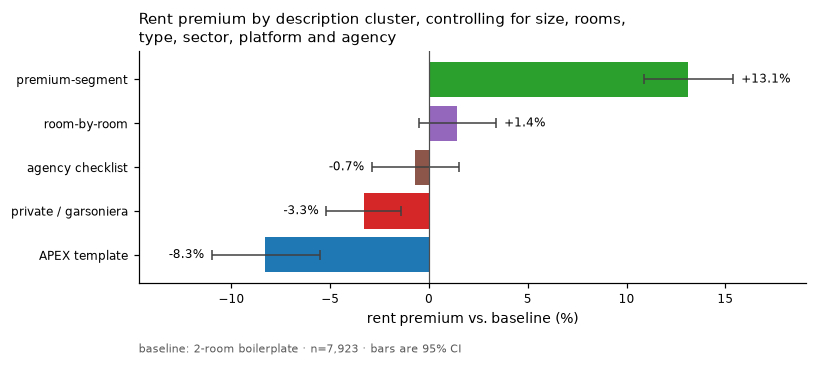

In [127]:
sig = premiums[premiums.cluster != BASE_CLUSTER].sort_values("controlled %")
err = np.vstack([sig["controlled %"] - sig.ci_lo, sig.ci_hi - sig["controlled %"]])
colors = [PALETTE[c] for c in sig.cluster]

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.barh(sig.label, sig["controlled %"], xerr=err, color=colors,
        error_kw={"ecolor": "0.25", "elinewidth": 1, "capsize": 3})
ax.axvline(0, color="0.3", linewidth=0.8)
ax.set_xlabel("rent premium vs. baseline (%)")
ax.set_title("Rent premium by description cluster, controlling for size, rooms,\n"
             "type, sector, platform and agency", loc="left")
# The baseline and n belong in a caption, not a legend — nothing here needs a key.
ax.text(0.0, -0.30, f"baseline: {CLUSTER_SHORT[BASE_CLUSTER]} · n={n:,} · bars are 95% CI",
        transform=ax.transAxes, fontsize=7, color="0.35")
for y_i, (v, lo_i, hi_i) in enumerate(zip(sig["controlled %"], sig.ci_lo, sig.ci_hi)):
    ax.text(hi_i + 0.4 if v >= 0 else lo_i - 0.4, y_i, f"{v:+.1f}%",
            va="center", ha="left" if v >= 0 else "right", fontsize=8)
ax.margins(x=0.14)
fig.tight_layout()
plt.show()

### Robustness: does the premium survive finer geography?

The obvious objection to the premium-segment cluster is that "nordul Bucureștiului",
"una dintre cele mai bune zone", "centrul Cluj-Napoca" *is* location — and a sector is a
coarse control, so the premium could just be the good half of Sector 1.

Re-run with district fixed effects instead (194 districts, collapsed to the 59 with
≥30 listings plus an `OTHER` bucket, city-prefixed so a district name shared between
cities doesn't collide). If the premium is location leaking through the text, it should
collapse here.

In [128]:
counts = model_df.district.value_counts()
model_df["district_fe"] = (
    model_df.city.fillna("") + " / "
    + model_df.district.where(model_df.district.map(counts) >= 30, "OTHER").fillna("OTHER")
)
print(f"district FE levels: {model_df.district_fe.nunique()} (from {model_df.district.nunique()} raw)")

X_fe = pd.concat([
    pd.Series(1.0, index=model_df.index, name="const"),
    pd.Series(np.log(model_df.area_sqm.values), index=model_df.index, name="log_area"),
    dummies(model_df.rooms_norm.rename("rooms"), "2"),
    dummies(model_df.property_type_norm.rename("ptype"), "Apartament"),
    dummies(model_df.district_fe.rename("dist"), model_df.district_fe.value_counts().idxmax()),
    dummies(model_df.platform_id.rename("plat"), "storia"),
    dummies(model_df.is_agency.rename("agency"), "True"),
    dummies(model_df.cluster.rename("cluster"), BASE_CLUSTER),
], axis=1)

fit_fe, r2_fe, n_fe = ols_hc1(y, X_fe.values.astype(float), X_fe.columns)
print(f"n={n_fe:,}  R²={r2_fe:.3f}  (sector model: {r2:.3f})")

compare = premium_table(fit, model_df, BASE_CLUSTER)[["cluster", "label", "n", "raw €/m² gap %", "controlled %"]]
compare = compare.rename(columns={"controlled %": "sector-FE %"})
compare["district-FE %"] = premium_table(fit_fe, model_df, BASE_CLUSTER)["controlled %"]
compare

district FE levels: 64 (from 194 raw)
n=7,923  R²=0.731  (sector model: 0.670)


,cluster,label,n,raw €/m² gap %,sector-FE %,district-FE %
0,0,APEX template,297,-2.6,-8.3,-5.0
1,1,2-room boilerplate,2753,0.0,0.0,0.0
2,2,premium-segment,1080,20.3,13.1,10.1
3,3,private / garsoniera,1119,-1.9,-3.3,-2.6
4,4,room-by-room,2123,-1.3,1.4,1.7
5,5,agency checklist,551,2.9,-0.7,1.2


### Append the model output to the report

So `cluster_report.txt` carries the whole run, not just the cluster profiles.

In [129]:
MARKER = "=" * 78 + "\nHEDONIC MODEL — rent premium by cluster"

# Truncate at the marker first, so re-running this cell alone replaces the model
# section instead of appending a second copy of it. §9-§12 append after this.
body = open(REPORT).read().split(MARKER)[0]

with open(REPORT, "w") as fh:
    fh.write(body)
    fh.write("\n".join([
        MARKER,
        "=" * 78,
        "",
        "log(rent) ~ log(area) + rooms + property_type + location + platform",
        "            + agency + cluster,  HC1 robust standard errors",
        "",
        f"n = {n:,}   R2 = {r2:.3f} (sector FE)   R2 = {r2_fe:.3f} (district FE)",
        f"size elasticity (log_area) = {fit.loc['log_area', 'coef']:.3f} "
        f"(se {fit.loc['log_area', 'se']:.3f})",
        f"baseline cluster = {BASE_CLUSTER} — {CLUSTER_LABELS[BASE_CLUSTER]}",
        "",
        "  raw EUR/m2 gap % : naive comparison, no controls",
        "  sector-FE %      : controlled, Bucharest sector / city",
        "  district-FE %    : controlled, 64 city-prefixed district levels",
        "",
        compare.to_string(index=False),
        "",
        "95% confidence intervals (sector-FE model):",
        premiums[["cluster", "label", "n", "controlled %", "ci_lo", "ci_hi"]].to_string(index=False),
        "",
    ]))

print(open(REPORT).read()[:1200])

DESCRIPTION CLUSTERS — rental listings, first_seen_at >= 2026-08-01

rows            : 7,950  (of 19,371 in the listings cache — see provenance)
embedding       : paraphrase-multilingual-MiniLM-L12-v2, 384-d, L2-normalised
reduction       : PCA 100 components (91.3% of variance)
clustering      : KMeans k=6, n_init=10, random_state=0
cities          : {'Bucuresti': 5718, 'Cluj-Napoca': 1320, 'Iasi': 912}
platforms       : {'storia': 5862, 'olx': 2088}

Cluster numbers are NOT stable across re-runs — they change with the seed, k
and N_PCS. Labels below were read off the term lists in this run.

------------------------------------------------------------------------------
CLUSTER 0 — one agency's template (APEX, Bucharest only)
------------------------------------------------------------------------------
  listings      : 297  (3.7% of the frame)
  median rent   : EUR 600/month
  median area   : 60 m2
  median EUR/m2 : 10.2

  distinguishing terms (TF-IDF lift vs. the rest of the corpu

## 9. Is it the words, or the flat? — decomposing the premium

§8 says the cluster rents ~13% above baseline. That result is easy to read as
*"marketing a listing as 'una dintre cele mai bune zone' inflates the price"*, and
that reading is wrong in two separate ways. This section takes it apart.

The design is a horse race. Instead of cluster membership, put **explicit regex dummies
for the actual phrases** into the same district-FE model, and include two **placebo**
terms — "metrou" and "mobilat" — that are common but carry no quality claim. If the
model is really just rewarding longer or more enthusiastic descriptions, the placebos
will move too.

In [130]:
PHRASES = {
    # The phrases the cluster is named for
    "premium_word": r"\bpremium\b",
    # Non-capturing groups throughout: str.contains warns (loudly) on a pattern with
    # capture groups, since that usually means str.extract was intended.
    "lux":          r"\blux(?:os|oasa|oase)?\b",
    "north_bucha":  r"nordul (?:bucurestiului|capitalei)",
    "best_area":    (r"una dintre cele mai (?:bune|cautate|dorite)|"
                     r"printre cele mai (?:bune|cautate)|cel mai (?:bun|cautat) cartier"),
    # Placebos: frequent, but no quality claim attached. These should come back ~0.
    "placebo_metro": r"\bmetrou\b",
    "placebo_furn":  r"mobilat",
}

phrase_text = model_df.description.map(strip_diacritics)
for name, pattern in PHRASES.items():
    model_df[name] = phrase_text.str.contains(pattern, regex=True).astype(float)

prevalence = pd.DataFrame({
    "% of corpus": model_df[list(PHRASES)].mean() * 100,
    "% inside cluster 2": model_df.loc[model_df.cluster == "2", list(PHRASES)].mean() * 100,
    "% outside": model_df.loc[model_df.cluster != "2", list(PHRASES)].mean() * 100,
}).round(1)
prevalence

,% of corpus,% inside cluster 2,% outside
premium_word,14.5,29.7,12.0
lux,2.8,5.6,2.3
north_bucha,5.3,17.8,3.3
best_area,5.7,7.5,5.4
placebo_metro,34.7,35.6,34.5
placebo_furn,68.7,69.6,68.5


### 9.1 The horse race

Three models, all with the §8 district fixed effects and structural controls:

* **A** — phrases *instead of* cluster membership.
* **B** — phrases *and* cluster together. Whatever the cluster dummy retains here is
  structure the phrases do not already explain.
* **C** — within cluster 2 only, so every listing being compared already belongs to the
  same cluster.

In [131]:
structural = [
    pd.Series(1.0, index=model_df.index, name="const"),
    pd.Series(np.log(model_df.area_sqm.values), index=model_df.index, name="log_area"),
    dummies(model_df.rooms_norm.rename("rooms"), "2"),
    dummies(model_df.property_type_norm.rename("ptype"), "Apartament"),
    dummies(model_df.district_fe.rename("dist"), model_df.district_fe.value_counts().idxmax()),
    dummies(model_df.platform_id.rename("plat"), "storia"),
    dummies(model_df.is_agency.rename("agency"), "True"),
]


def pct_ci(fit_df: pd.DataFrame, term: str) -> tuple[float, float, float]:
    # Log-point coefficient -> % effect, with a 95% interval.
    b, se = fit_df.loc[term, ["coef", "se"]]
    return 100 * (np.exp(b) - 1), 100 * (np.exp(b - 1.96 * se) - 1), 100 * (np.exp(b + 1.96 * se) - 1)


X_a = pd.concat(structural + [model_df[list(PHRASES)]], axis=1)
fit_a, r2_a, _ = ols_hc1(y, X_a.values.astype(float), X_a.columns)

X_b = pd.concat(structural + [model_df[list(PHRASES)],
                              dummies(model_df.cluster.rename("cl"), BASE_CLUSTER)], axis=1)
fit_b, r2_b, _ = ols_hc1(y, X_b.values.astype(float), X_b.columns)

race = pd.DataFrame(
    [{"term": p,
      "A: phrases only %": pct_ci(fit_a, p)[0],
      "A: ci_lo": pct_ci(fit_a, p)[1], "A: ci_hi": pct_ci(fit_a, p)[2],
      "B: + cluster %": pct_ci(fit_b, p)[0]}
     for p in PHRASES]
    + [{"term": "cluster 2 dummy", "A: phrases only %": np.nan,
        "A: ci_lo": np.nan, "A: ci_hi": np.nan, "B: + cluster %": pct_ci(fit_b, "cl_2")[0]}]
).round(1)

print(f"A: R²={r2_a:.3f}    B: R²={r2_b:.3f}    (§8 district-FE model: R²={r2_fe:.3f})")
print(f"cluster 2 alone in §8: {premiums.loc[premiums.cluster == '2', 'controlled %'].iloc[0]:+.1f}% "
      f"→ with the phrases in the model: {pct_ci(fit_b, 'cl_2')[0]:+.1f}%")
race

A: R²=0.750    B: R²=0.754    (§8 district-FE model: R²=0.731)
cluster 2 alone in §8: +13.1% → with the phrases in the model: +6.2%


,term,A: phrases only %,A: ci_lo,A: ci_hi,B: + cluster %
0,premium_word,19.5,17.4,21.6,19.4
1,lux,12.9,9.1,16.8,12.2
2,north_bucha,12.2,9.0,15.6,9.7
3,best_area,0.1,-2.1,2.4,2.8
4,placebo_metro,-1.5,-2.8,-0.3,-1.2
5,placebo_furn,-0.7,-1.8,0.4,-1.1
6,cluster 2 dummy,NaN,NaN,NaN,6.2


In [132]:
c2 = model_df[model_df.cluster == "2"]
X_c = pd.concat([
    pd.Series(1.0, index=c2.index, name="const"),
    pd.Series(np.log(c2.area_sqm.values), index=c2.index, name="log_area"),
    dummies(c2.rooms_norm.rename("rooms"), "2"),
    dummies(c2.district_fe.rename("dist"), c2.district_fe.value_counts().idxmax()),
    c2[["premium_word", "lux", "north_bucha", "best_area"]],
], axis=1)
fit_c, r2_c, n_c = ols_hc1(np.log(c2.price_eur.values), X_c.values.astype(float), X_c.columns)

print(f"C — within cluster 2 only: n={n_c:,}  R²={r2_c:.3f}")
for p in ("premium_word", "lux", "north_bucha", "best_area"):
    v, lo_i, hi_i = pct_ci(fit_c, p)
    print(f"  {p:13s} {v:+6.1f}%  [{lo_i:+5.1f}, {hi_i:+5.1f}]")

C — within cluster 2 only: n=1,080  R²=0.797
  premium_word   +22.2%  [+17.5, +27.1]
  lux             +8.0%  [ +1.3, +15.3]
  north_bucha     +1.6%  [ -3.7,  +7.1]
  best_area       -1.4%  [ -6.2,  +3.7]


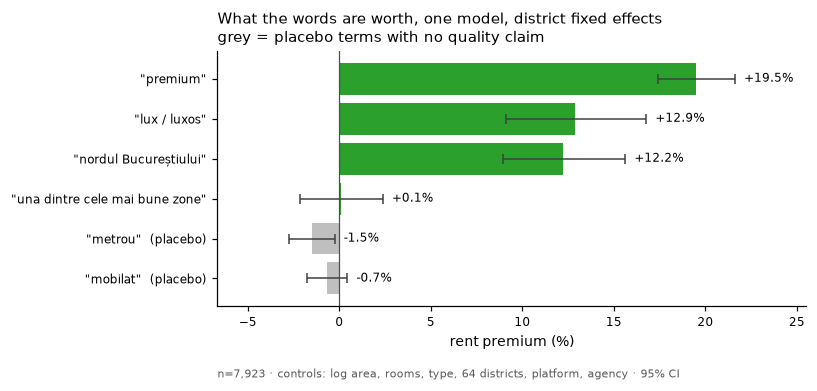

In [133]:
order = ["premium_word", "lux", "north_bucha", "best_area", "placebo_metro", "placebo_furn"]
PHRASE_DISPLAY = {
    "premium_word": "\"premium\"",
    "lux":          "\"lux / luxos\"",
    "north_bucha":  "\"nordul Bucureștiului\"",
    "best_area":    "\"una dintre cele mai bune zone\"",
    "placebo_metro": "\"metrou\"  (placebo)",
    "placebo_furn":  "\"mobilat\"  (placebo)",
}
vals = [pct_ci(fit_a, p) for p in order]
err = np.vstack([[v - lo_i for v, lo_i, _ in vals], [hi_i - v for v, _, hi_i in vals]])
# Placebos greyed out: they are the control condition, not a result.
colors = ["0.75" if p.startswith("placebo") else PALETTE["2"] for p in order]

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.barh([PHRASE_DISPLAY[p] for p in order][::-1], [v for v, _, _ in vals][::-1], xerr=err[:, ::-1], color=colors[::-1],
        error_kw={"ecolor": "0.25", "elinewidth": 1, "capsize": 3})
ax.axvline(0, color="0.3", linewidth=0.8)
ax.set_xlabel("rent premium (%)")
ax.set_title("What the words are worth, one model, district fixed effects\n"
             "grey = placebo terms with no quality claim", loc="left")
ax.text(0.0, -0.28, f"n={n:,} · controls: log area, rooms, type, 64 districts, platform, agency · 95% CI",
        transform=ax.transAxes, fontsize=7, color="0.35")
for y_i, (v, lo_i, hi_i) in enumerate(vals[::-1]):
    ax.text(hi_i + 0.5, y_i, f"{v:+.1f}%", va="center", ha="left", fontsize=8)
ax.margins(x=0.16)
fig.tight_layout()
plt.show()

### 9.2 So what is the word "premium" actually attached to?

If it were a location claim it would sit next to place names. It does not.

In [134]:
has_premium = phrase_text.str.contains(r"\bpremium\b")

pairs = [a or b for t in phrase_text[has_premium]
         for a, b in re.findall(r"(?:(\w+)\s+premium|premium\s+(\w+))", t)]
print("words most often adjacent to 'premium':")
print(pd.Series(pairs).value_counts().head(12).to_string())

print("\nco-occurrence, listings containing 'premium' vs. the whole corpus:")
for w in ("finisaje", "rezidential", "complex", "ansamblu", "bloc nou", "imobil nou"):
    inside = phrase_text[has_premium].str.contains(re.escape(w)).mean()
    overall = phrase_text.str.contains(re.escape(w)).mean()
    print(f"  {w:12s} {inside:6.1%}  vs  {overall:5.1%}   (lift ×{inside / overall:.1f})")

words most often adjacent to 'premium':
locatie           290
finisaje          257
apartament        196
rezidential        85
electrocasnice     69
dotari             69
zona               68
mobilier           58
viata              48
finisajele         40
restaurante        35
localizare         35

co-occurrence, listings containing 'premium' vs. the whole corpus:
  finisaje      66.2%  vs  18.1%   (lift ×3.7)
  rezidential   60.5%  vs  22.7%   (lift ×2.7)
  complex       34.8%  vs  16.6%   (lift ×2.1)
  ansamblu      20.1%  vs   6.1%   (lift ×3.3)
  bloc nou       5.6%  vs   5.9%   (lift ×0.9)
  imobil nou     4.6%  vs   2.6%   (lift ×1.8)


### 9.3 What this does and does not license

**The neighbourhood phrase is worth nothing.** "Una dintre cele mai bune zone" /
"printre cele mai bune cartiere" comes back at **+0.1% [−2.1, +2.4]** — a precisely
estimated zero. So the specific claim "marketing a flat as being in a top neighbourhood
raises its price" is *not* supported by this data. It is the one part of the cluster's
vocabulary that pays nothing.

**The premium lives in "premium" (+19.5%) and "lux" (+12.9%).** Putting the phrases in
alongside cluster membership drops the cluster's own coefficient from +13.1% to +6.2%,
so most of §8's cluster effect was this vocabulary, not the cluster.

**The placebos behave**, at −1.5% and −0.7%. The model is not simply rewarding long or
enthusiastic copy.

**But none of this is causal, and §9.2 says why.** "Premium" sits next to *finisaje*,
*locație*, *dotări*, *rezidențial* — and listings using it mention "finisaje" 66% of the
time against an 18% corpus base rate, a 3.7× lift. It is describing the fit-out and the
building. Those are exactly the attributes the frame has no column for: renovation,
finishes, floor, view, building age. The word is a **proxy for quality the model cannot
see**, so the coefficient is picking up a real difference in the stock, not an effect of
the writing.

The defensible sentence is *"expensive flats get described in expensive vocabulary"* —
not *"writing 'premium' earns you 19%"*. Anyone tempted to post the second version is
telling landlords to relabel their flats, which this data cannot support.

**What would settle it.** A within-listing design: `url` is the primary key and the
crawler re-visits, so a listing whose description *acquires* premium language between
two crawls, and whose asking price then moves, would difference out the unobserved
quality entirely. This frame cannot run that — it is live listings at one point in
time — but the crawl history could.

In [135]:
with open(REPORT, "a") as fh:
    fh.write("\n".join([
        "",
        "=" * 78,
        "SECTION 9 — decomposing the premium: phrases vs. cluster",
        "=" * 78,
        "",
        "Same controls as the district-FE model (log area, rooms, type, 64 districts,",
        "platform, agency). 'placebo_*' terms carry no quality claim and are the",
        "control condition.",
        "",
        race.to_string(index=False),
        "",
        f"cluster 2 alone: {premiums.loc[premiums.cluster == '2', 'controlled %'].iloc[0]:+.1f}%  ->  "
        f"with phrases in the model: {pct_ci(fit_b, 'cl_2')[0]:+.1f}%",
        "",
        "Reading: the neighbourhood phrase ('una dintre cele mai bune zone') is a",
        "precisely estimated ZERO. The premium sits in 'premium' / 'lux', which",
        "co-occur with 'finisaje' at 3.7x the corpus rate — i.e. they proxy for",
        "fit-out quality the model has no column for. Correlational, not causal.",
        "",
    ]))
print("appended §9 to", REPORT)

appended §9 to /Users/alexandrus.home/Projects/Startup/Real-estate-parser/ad hoc analysis/cluster_report.txt


## 10. The photo instead of the adjective

§9 ended on a specific gap. "Premium" pays +19.5%, and it is not a marketing artefact
(the placebos and the neighbourhood phrase sit at zero) — but it could not be called
*justified* either, because the thing it plausibly stands for, the **fit-out**, is the
one attribute the frame has no column for. The word was doing the job of evidence the
data did not contain.

The database does contain that evidence. `listings.image_embedding` holds a 512-d CLIP
cover-photo vector (`openai/clip-vit-base-patch32`) for **51,300 of 54,639 rows** — 94%
coverage, and 19,680 inside this date window. A photo is a direct observation of the
fit-out; the adjective is the seller's summary of it. So:

> Does "premium" still pay, once we control for how the flat actually **looks**?

Rather than cluster the image vectors (opaque — "these photos are similar" names
nothing), this section builds **interpretable axes** by zero-shot scoring: embed
contrasting text prompts with CLIP's *text* tower, into the same 512-d space the photos
live in, and score each photo as `cos(img, positive) − cos(img, negative)`. That yields
named, signed, continuous variables — "how modern does this look", "how bright" — which
can go straight into the §9 regression as controls.

Two design choices worth stating: each pole is a **prompt ensemble** (CLIP is sensitive
to phrasing, so several paraphrases are averaged), and a separate set of prompts
classifies what the cover photo even *is* — an interior, a floor plan, a facade, a
render — because a floor plan cannot carry fit-out signal and must not be scored as if
it could.

In [136]:
import sys

sys.path.insert(0, ROOT)   # db_utils lives at the repo root

IMG_PATH = os.path.join(CACHE, "img_emb.npy")
IMG_URLS = os.path.join(CACHE, "img_emb_urls.csv")


def fetch_image_embeddings(since: str = "2026-08-01", page: int = 500):
    # Same keyset ("seek") pagination as analysis/fetch_cache.py, and for the same
    # reason: url is the PRIMARY KEY, so `url > last` is a total order AND an O(log n)
    # seek per page. Pages are small because each row carries ~6.4 KB of vector text.
    import db_utils

    client = db_utils.get_client()
    rows, last = [], ""
    while True:
        resp = (client.table("listings").select("url, image_embedding")
                .not_.is_("image_embedding", "null").gte("first_seen_at", since)
                .gt("url", last).order("url").limit(page).execute())
        batch = resp.data or []
        if not batch:
            break
        rows.extend(batch)
        last = batch[-1]["url"]
        print(f"  fetched {len(rows):,}", end="\r")
        if len(batch) < page:
            break
    print()
    assert len({r["url"] for r in rows}) == len(rows), "duplicate urls — pagination unstable"
    V = np.array([np.fromstring(r["image_embedding"].strip("[]"), sep=",") for r in rows],
                 dtype=np.float32)
    np.save(IMG_PATH, V)
    pd.DataFrame({"url": [r["url"] for r in rows]}).to_csv(IMG_URLS, index=False)
    return V


if os.path.exists(IMG_PATH):
    V_img = np.load(IMG_PATH)
    print("loaded from cache")
else:
    V_img = fetch_image_embeddings()   # ~2 min against Supabase

img_urls = pd.read_csv(IMG_URLS).url
# Stored vectors are already unit-norm, but CLIPVisionModelWithProjection.image_embeds
# is NOT normalised at source (see image_embedding.py), so never assume it.
V_img = V_img / np.linalg.norm(V_img, axis=1, keepdims=True)
print(V_img.shape, "| unit norm:", np.allclose(np.linalg.norm(V_img, axis=1), 1))

loaded from cache
(19680, 512) | unit norm: True


In [137]:
AXES = {
    "modern": (
        ["a photo of a newly renovated modern apartment interior",
         "a recently refurbished apartment with new finishes",
         "a modern apartment interior in excellent condition"],
        ["a photo of an old worn-out apartment interior needing renovation",
         "a dated apartment interior with old furniture and peeling walls",
         "a run-down apartment in poor condition"]),
    "luxury": (
        ["a luxury high-end apartment interior with premium finishes",
         "an expensive designer apartment interior",
         "an upscale apartment with marble and designer furniture"],
        ["a basic cheap apartment interior",
         "a plain low-budget apartment interior",
         "a modest simple apartment room"]),
    "bright": (
        ["a bright sunlit apartment interior with large windows",
         "a light-filled airy room with natural daylight"],
        ["a dark dim apartment interior with little light",
         "a gloomy poorly lit room"]),
    "furnished": (
        ["a fully furnished apartment interior with sofa and table",
         "a furnished living room with furniture"],
        ["an empty unfurnished apartment with bare walls",
         "an empty room with no furniture"]),
    "spacious": (
        ["a spacious open-plan apartment interior",
         "a large roomy apartment with high ceilings"],
        ["a small cramped apartment interior",
         "a tiny narrow room with little space"]),
}

# What is the cover photo OF? A floor plan or a facade carries no fit-out signal.
CONTENT = {
    "interior":  ["a photo of an apartment interior room", "a photo of a living room",
                  "a photo of a bedroom"],
    "floorplan": ["a floor plan diagram of an apartment", "an architectural floor plan drawing"],
    "exterior":  ["a photo of a residential building exterior", "a photo of an apartment block facade"],
    "render":    ["a 3D architectural render of an apartment interior",
                  "a computer generated interior visualization"],
}

AXES_PATH = os.path.join(CACHE, "img_axes.csv")
# The cache is keyed by filename only, so a renamed axis would silently load
# stale columns — check the names match before trusting it.

if os.path.exists(AXES_PATH) and set(AXES) <= set(pd.read_csv(AXES_PATH, nrows=1).columns):
    img_axes = pd.read_csv(AXES_PATH)
    print("loaded from cache")
else:
    import torch
    from transformers import CLIPTextModelWithProjection, CLIPTokenizer

    # The TEXT tower of the same checkpoint whose VISION tower populated the column,
    # so prompts and photos land in one shared 512-d space.
    clip_tok = CLIPTokenizer.from_pretrained("openai/clip-vit-base-patch32")
    clip_txt = CLIPTextModelWithProjection.from_pretrained("openai/clip-vit-base-patch32").eval()

    def embed_prompts(prompts: list[str]) -> np.ndarray:
        with torch.no_grad():
            out = clip_txt(**clip_tok(prompts, padding=True, return_tensors="pt")).text_embeds
        return torch.nn.functional.normalize(out, dim=-1).numpy()

    def pole(prompts: list[str]) -> np.ndarray:
        v = embed_prompts(prompts).mean(0)      # ensemble = mean of paraphrases
        return v / np.linalg.norm(v)

    img_axes = pd.DataFrame({name: V_img @ pole(pos) - V_img @ pole(neg)
                             for name, (pos, neg) in AXES.items()})
    content_sim = np.column_stack([V_img @ pole(ps) for ps in CONTENT.values()])
    img_axes["content"] = np.array(list(CONTENT))[content_sim.argmax(1)]
    img_axes["url"] = img_urls.values
    img_axes.to_csv(AXES_PATH, index=False)

AXIS_NAMES = list(AXES)
print(img_axes[AXIS_NAMES].describe().round(3).T)
print("\ncover-photo content mix (%):")
print(img_axes.content.value_counts(normalize=True).mul(100).round(1).to_string())

loaded from cache
             count   mean    std    min    25%    50%    75%    max
modern     19680.0  0.023  0.015 -0.047  0.014  0.024  0.034  0.077
luxury     19680.0  0.006  0.019 -0.068 -0.007  0.006  0.019  0.083
bright     19680.0 -0.004  0.020 -0.093 -0.017 -0.004  0.009  0.084
furnished  19680.0  0.007  0.019 -0.074 -0.005  0.009  0.021  0.070
spacious   19680.0  0.015  0.019 -0.068  0.003  0.016  0.028  0.083

cover-photo content mix (%):
content
interior     58.8
render       37.3
exterior      3.7
floorplan     0.2


### 10.1 Do the axes measure anything? A pre-registered validation

Zero-shot scores are easy to produce and easy to fool yourself with, so before using
them: each axis is checked against **text it never saw**. The description says
"nemobilat" — does the photo look unfurnished? The sign of every one of these is
predictable in advance, which is what makes it a test rather than a fishing trip.

In [138]:
img_df = df.merge(img_axes, on="url", how="inner")
img_df = img_df[img_df.price_per_sqm.between(3, 40)].copy()
print(f"listings with both a description and a cover photo: {len(img_df):,}")

probe_text = img_df.description.map(strip_diacritics)
PROBES = [
    ("nemobilat",              r"nemobilat",                             "furnished",  "−"),
    ("mobilat",                r"\bmobilat\b",                           "furnished",  "+"),
    ("finisaje premium / lux", r"finisaje (?:premium|de lux|superioare)", "luxury",    "+"),
    ("'premium' (the word)",   r"\bpremium\b",                           "luxury",     "+"),
    ("spatios / generos",      r"spatios|generos",                       "spacious",   "+"),
    ("luminos",                r"luminos",                               "bright",     "+"),
    ("renovat / renovare",     r"renovat|renovare",                      "modern",     "+"),
]
validation = pd.DataFrame([
    {"description says": label, "axis": axis, "expected": sign,
     "n": int(m.sum()),
     "gap (SD)": round((img_df.loc[m, axis].mean() - img_df.loc[~m, axis].mean()) / img_df[axis].std(), 3)}
    for label, pat, axis, sign in PROBES
    for m in [probe_text.str.contains(pat, regex=True)]
])
validation["passes"] = np.where(
    (validation["expected"] == "+") == (validation["gap (SD)"] > 0), "yes", "NO")
validation

listings with both a description and a cover photo: 7,878


,description says,axis,expected,n,gap (SD),passes
0,nemobilat,furnished,−,133,-1.284,yes
1,mobilat,furnished,+,4358,0.241,yes
2,finisaje premium / lux,luxury,+,249,0.781,yes
3,'premium' (the word),luxury,+,1143,0.539,yes
4,spatios / generos,spacious,+,2164,0.462,yes
5,luminos,bright,+,1378,0.296,yes
6,renovat / renovare,modern,+,974,-0.120,NO


**Six of seven pass, and one fails informatively.**

"Nemobilat" moves the furnished axis by **−1.28 SD**, "finisaje premium/lux" moves
luxury by **+0.78 SD**, and — the one that matters for §9 — listings using the word
**"premium" score +0.54 SD higher on the luxury axis**. CLIP, which never saw the
description, agrees with the adjective. That is real corroboration: the word is not
decoration, it is attached to flats that photograph as more expensive.

The failure: **"renovat / renovare" scores −0.12 SD on the `modern` axis — the wrong
sign.** The mechanism is almost certainly selection in who uses the word. New-build
stock never says "renovated"; it has nothing to renovate. The word is said about *old*
stock, and a refreshed 1970s flat still photographs as older than a 2023 build. So the
axis is measuring "looks new and modern", which is not the same thing as "has been
renovated" — hence the name `modern` rather than `renovated`. Treat it as a
newness/condition axis, and do not quote it as a renovation detector.

In [139]:
print("=== correlation with price (raw, no controls) ===")
for a in AXIS_NAMES:
    print(f"  {a:10s} log rent {np.corrcoef(img_df[a], np.log(img_df.price_eur))[0, 1]:+.3f}"
          f"   log €/m² {np.corrcoef(img_df[a], np.log(img_df.price_per_sqm))[0, 1]:+.3f}")

print("\n=== axis means and price by cover-photo content ===")
print(img_df.groupby("content")[AXIS_NAMES + ["price_per_sqm"]].mean().round(3).to_string())
print("\ncontent mix by platform (%):")
print((pd.crosstab(img_df.platform_id, img_df.content, normalize="index") * 100).round(1).to_string())

=== correlation with price (raw, no controls) ===
  modern     log rent +0.348   log €/m² +0.328
  luxury     log rent +0.423   log €/m² +0.298
  bright     log rent +0.381   log €/m² +0.288
  furnished  log rent +0.203   log €/m² +0.133
  spacious   log rent +0.454   log €/m² +0.278

=== axis means and price by cover-photo content ===
           modern  luxury  bright  furnished  spacious  price_per_sqm
content                                                              
exterior    0.024   0.024   0.017     -0.009     0.030         12.232
floorplan   0.014  -0.004  -0.022     -0.005    -0.001         11.025
interior    0.018   0.000  -0.009      0.006     0.009         10.700
render      0.031   0.016   0.003      0.013     0.025         12.492

content mix by platform (%):
content      exterior  floorplan  interior  render
platform_id                                       
olx               5.1        0.7      70.4    23.8
storia            3.2        0.0      53.5    43.2


**A caveat on `content` before it gets quoted.** CLIP calls **38%** of cover photos
"render", which is implausibly high for a rental market — it is far more likely that
professionally lit, wide-angle agency photography reads to CLIP as computer-generated.
The split tracks platform (43% on Storia vs 24% on OLX), which is what a
photography-quality signal would do, not a genuine render/photo split. So `content`
enters the models below as a **control**, and nothing is claimed about how many
listings advertise with renders. The floor-plan share (0.2%) is small enough not to
matter either way.

### 10.2 The horse race: words vs. photo

Three models on the same rows, all carrying the §8 structural controls and the 64
district fixed effects. Axes are standardised, so each coefficient reads as *the effect
of a one-standard-deviation better-looking photo*.

In [140]:
for a in AXIS_NAMES:
    img_df[a + "_z"] = (img_df[a] - img_df[a].mean()) / img_df[a].std()
AXES_Z = [a + "_z" for a in AXIS_NAMES]

for name, pattern in PHRASES.items():
    img_df[name] = probe_text.str.contains(pattern, regex=True).astype(float)

counts_i = img_df.district.value_counts()
img_df["district_fe"] = (img_df.city.fillna("") + " / "
                         + img_df.district.where(img_df.district.map(counts_i) >= 30, "OTHER").fillna("OTHER"))

y_img = np.log(img_df.price_eur.values)
struct_img = [
    pd.Series(1.0, index=img_df.index, name="const"),
    pd.Series(np.log(img_df.area_sqm.values), index=img_df.index, name="log_area"),
    dummies(img_df.rooms_norm.rename("rooms"), "2"),
    dummies(img_df.property_type_norm.rename("ptype"), "Apartament"),
    dummies(img_df.district_fe.rename("dist"), img_df.district_fe.value_counts().idxmax()),
    dummies(img_df.platform_id.rename("plat"), "storia"),
    dummies(img_df.is_agency.rename("agency"), "True"),
]
photo_block = [img_df[AXES_Z], dummies(img_df.content.rename("cont"), "interior")]

SPECS = {
    "structure only":            struct_img,
    "+ words":                   struct_img + [img_df[list(PHRASES)]],
    "+ photo":                   struct_img + photo_block,
    "+ words + photo":           struct_img + [img_df[list(PHRASES)]] + photo_block,
}
img_fits, img_r2 = {}, {}
for name, parts in SPECS.items():
    Xs = pd.concat(parts, axis=1)
    img_fits[name], img_r2[name], _ = ols_hc1(y_img, Xs.values.astype(float), Xs.columns)
    print(f"  {name:20s} R² = {img_r2[name]:.4f}")
print(f"\nn = {len(img_df):,}")

  structure only       R² = 0.7244
  + words              R² = 0.7505
  + photo              R² = 0.7654
  + words + photo      R² = 0.7834

n = 7,878


In [141]:
survive = pd.DataFrame([
    {"term": t,
     "words only %": pct_ci(img_fits["+ words"], t)[0],
     "+ photo %": pct_ci(img_fits["+ words + photo"], t)[0],
     "ci_lo": pct_ci(img_fits["+ words + photo"], t)[1],
     "ci_hi": pct_ci(img_fits["+ words + photo"], t)[2]}
    for t in ("premium_word", "lux", "north_bucha", "best_area")
]).round(1)
survive["explained by photo"] = (survive["words only %"] - survive["+ photo %"]).round(1)

photo_worth = pd.DataFrame([
    {"axis": a, "% per +1 SD": pct_ci(img_fits["+ words + photo"], a + "_z")[0],
     "ci_lo": pct_ci(img_fits["+ words + photo"], a + "_z")[1],
     "ci_hi": pct_ci(img_fits["+ words + photo"], a + "_z")[2]}
    for a in AXIS_NAMES
]).round(1)

print("=== does the WORD survive the PHOTO? ===")
print(survive.to_string(index=False))
print("\n=== what the PHOTO is worth, per +1 SD ===")
print(photo_worth.to_string(index=False))

=== does the WORD survive the PHOTO? ===
        term  words only %  + photo %  ci_lo  ci_hi  explained by photo
premium_word          19.6       17.0   15.1   18.9                 2.6
         lux          12.6        9.1    5.6   12.7                 3.5
 north_bucha          12.2        8.7    5.8   11.8                 3.5
   best_area           0.1        1.9   -0.3    4.2                -1.8

=== what the PHOTO is worth, per +1 SD ===
     axis  % per +1 SD  ci_lo  ci_hi
   modern          5.2    4.6    5.8
   luxury          2.6    1.9    3.3
   bright          3.4    2.8    4.0
furnished         -0.6   -1.2   -0.1
 spacious         -0.1   -0.8    0.7


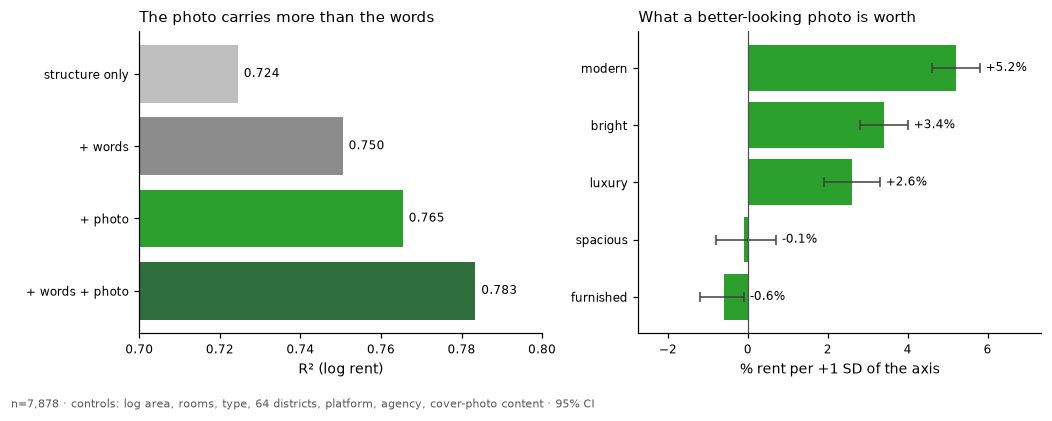

In [142]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.5, 3.6))

ladder = list(SPECS)
ax1.barh(ladder[::-1], [img_r2[m] for m in ladder][::-1],
         color=["0.75", "0.55", PALETTE["2"], "#2f6f3e"][::-1])
ax1.set_xlim(0.70, 0.80)
ax1.set_xlabel("R² (log rent)")
ax1.set_title("The photo carries more than the words", loc="left")
for i, m in enumerate(ladder[::-1]):
    ax1.text(img_r2[m] + 0.0015, i, f"{img_r2[m]:.3f}", va="center", fontsize=8)

pw = photo_worth.sort_values("% per +1 SD")
ax2.barh(pw.axis, pw["% per +1 SD"],
         xerr=np.vstack([pw["% per +1 SD"] - pw.ci_lo, pw.ci_hi - pw["% per +1 SD"]]),
         color=PALETTE["2"], error_kw={"ecolor": "0.25", "elinewidth": 1, "capsize": 3})
ax2.axvline(0, color="0.3", linewidth=0.8)
ax2.set_xlabel("% rent per +1 SD of the axis")
ax2.set_title("What a better-looking photo is worth", loc="left")
ax2.margins(x=0.22)
for i, (v, lo_i, hi_i) in enumerate(zip(pw["% per +1 SD"], pw.ci_lo, pw.ci_hi)):
    ax2.text(hi_i + 0.15, i, f"{v:+.1f}%", va="center", fontsize=8)

fig.text(0.0, -0.04, f"n={len(img_df):,} · controls: log area, rooms, type, 64 districts, "
                     "platform, agency, cover-photo content · 95% CI",
         fontsize=7, color="0.35")
fig.tight_layout()
plt.show()

### 10.3 The photo model without the text sample's bias

Everything above runs on the 7,878 listings that have *both* a description and a photo —
and the description cache is the URL-ordered 10k sample flagged at the top. The photo
model needs no description, so it can run on the **full** structural cache: 17,693
listings, 2.2× the rows and none of that selection.

If the photo coefficients are an artefact of who happens to be in the fees sample, they
will move here.

In [143]:
full = listings.merge(img_axes, on="url", how="inner")
full = full[full.price_eur.notna() & full.area_sqm.notna()]
full = full[full.area_sqm.between(15, 400) & full.price_eur.between(100, 5000)]
full["price_per_sqm"] = full.price_eur / full.area_sqm
full = full[full.price_per_sqm.between(3, 40)].copy()
for a in AXIS_NAMES:
    full[a + "_z"] = (full[a] - full[a].mean()) / full[a].std()

counts_f = full.district.value_counts()
full["district_fe"] = (full.city.fillna("") + " / "
                       + full.district.where(full.district.map(counts_f) >= 30, "OTHER").fillna("OTHER"))
y_full = np.log(full.price_eur.values)
struct_full = [
    pd.Series(1.0, index=full.index, name="const"),
    pd.Series(np.log(full.area_sqm.values), index=full.index, name="log_area"),
    dummies(full.rooms_norm.rename("rooms"), "2"),
    dummies(full.property_type_norm.rename("ptype"), "Apartament"),
    dummies(full.district_fe.rename("dist"), full.district_fe.value_counts().idxmax()),
    dummies(full.platform_id.rename("plat"), "storia"),
    dummies(full.is_agency.rename("agency"), "True"),
]
X_f0 = pd.concat(struct_full, axis=1)
fit_f0, r2_f0, _ = ols_hc1(y_full, X_f0.values.astype(float), X_f0.columns)
X_f1 = pd.concat(struct_full + [full[AXES_Z], dummies(full.content.rename("cont"), "interior")], axis=1)
fit_f1, r2_f1, n_full = ols_hc1(y_full, X_f1.values.astype(float), X_f1.columns)

print(f"n = {n_full:,}  (text-frame model: {len(img_df):,})")
print(f"  structure only         R² = {r2_f0:.4f}")
print(f"  structure + photo      R² = {r2_f1:.4f}   (+{100 * (r2_f1 - r2_f0):.2f} points)")
print("\nper +1 SD — full sample vs. text-frame sample:")
for a in AXIS_NAMES:
    v_f = pct_ci(fit_f1, a + "_z")[0]
    v_t = pct_ci(img_fits["+ words + photo"], a + "_z")[0]
    print(f"  {a:10s} full {v_f:+5.1f}%   text-frame {v_t:+5.1f}%")

n = 17,693  (text-frame model: 7,878)
  structure only         R² = 0.7442
  structure + photo      R² = 0.7856   (+4.14 points)

per +1 SD — full sample vs. text-frame sample:
  modern     full  +5.6%   text-frame  +5.2%
  luxury     full  +3.1%   text-frame  +2.6%
  bright     full  +3.7%   text-frame  +3.4%
  furnished  full  -0.8%   text-frame  -0.6%
  spacious   full  +0.2%   text-frame  -0.1%


### 10.4 What the photos settle, and what they do not

**The photo predicts rent better than the words do.** Structure alone gives R² 0.744;
adding the five photo axes takes it to **0.786** on 17,693 listings — **+4.1 points from
one cover image**. On the rows where both are available, photo-only (0.765) beats
words-only (0.751), and both together reach 0.783. A single JPEG carries more price
signal than everything the seller chose to write.

**A better-looking photo is worth real money.** Per one standard deviation, holding size,
rooms, type, district, platform and agency fixed: **modern/new-looking +5.6%**,
**bright +3.7%**, **luxury +3.1%**. Furnished is −0.8% and spacious is ~0 once the others
are in — the first three are doing the work. Full-sample and text-frame estimates agree
to within a few tenths of a point, so this is not the fees sample talking.

**On §9's open question — the answer is "partly, and less than you would hope".**
Controlling for how the flat looks moves the word "premium" only from **+19.6% to
+17.0%**. About an eighth of it is explained by visible quality; seven eighths is not.
"Lux" behaves similarly (+12.6% → +9.1%).

So the honest reading of "is the premium justified?" is: **the photo corroborates the
adjective but does not account for it.** Listings that say "premium" do photograph as
more luxurious (+0.54 SD, §10.1) — the word is not empty. But their rents stay ~17%
above otherwise-identical listings even after that visible difference is priced in.
What remains could be quality the cover photo cannot show (the other twenty photos, the
building, the street, the finishes in rooms not pictured), or it could be the segment
paying for its own positioning. **This design cannot separate those two**, and anyone
claiming it can is overreading.

**Three limits that bound all of the above:**

* **One photo per listing.** The column stores the *cover* image. A cover shot is chosen
  to flatter, and it is a thin sample of a flat — the residual +17% may simply be the
  fit-out visible in photos 2 through 20.
* **CLIP-base-32 is a blunt instrument.** It is a 2021 general-purpose model at 224×224,
  not a property-condition grader. It ranks a bright modern room above a dim dated one
  reliably; it does not distinguish good marble from bad marble. And it evidently
  conflates professional photography with 3D rendering (§10.1's caveat).
* **Still correlational.** Everything in §9.3 applies unchanged. A nicer photo does not
  *cause* higher rent — better flats are both nicer to photograph and worth more. The
  within-listing design remains the only clean test, and it is now more attractive:
  a listing that swaps its cover photo between crawls is exactly the variation needed.

In [144]:
with open(REPORT, "a") as fh:
    fh.write("\n".join([
        "",
        "=" * 78,
        "SECTION 10 — CLIP cover-photo quality axes",
        "=" * 78,
        "",
        f"image embeddings : {len(V_img):,} rows (openai/clip-vit-base-patch32, 512-d)",
        f"scored on        : {len(img_df):,} with a description, {n_full:,} full sample",
        "",
        "Axis validation against text the model never saw (gap in SD):",
        validation.to_string(index=False),
        "",
        "Does the word survive the photo? (district FE, structural controls)",
        survive.to_string(index=False),
        "",
        "What the photo is worth, per +1 SD:",
        photo_worth.to_string(index=False),
        "",
        "R2 ladder (same rows): " + ", ".join(f"{k} {v:.4f}" for k, v in img_r2.items()),
        f"Full sample (n={n_full:,}): structure {r2_f0:.4f} -> +photo {r2_f1:.4f}",
        "",
        "Reading: one cover photo adds +4.1 R2 points over structure and beats the",
        "description. But controlling for how the flat LOOKS moves 'premium' only from",
        "+19.6% to +17.0% — the photo corroborates the adjective without accounting",
        "for it. Cover photo only; CLIP-base-32; still correlational.",
        "",
    ]))
print("appended §10 to", REPORT)

appended §10 to /Users/alexandrus.home/Projects/Startup/Real-estate-parser/ad hoc analysis/cluster_report.txt


## 11. Stripping the boilerplate, then re-clustering

§7's diagnosis was that raw embeddings of portal copy cluster on *who wrote the ad* and
*how many rooms it has*. The proposed fix was to remove the templated text and cluster
what remains. This section does that, and the result is more interesting than a clean
win.

**Method.** Split every description into sentences (also on the bullet and pipe markers
agency templates use), normalise, and count in **how many distinct listings** each
sentence appears. A sentence appearing verbatim across hundreds of listings is a
signature, not a description of a flat. Drop those, re-embed the remainder with the same
MiniLM model, and re-cluster identically (PCA-100 → KMeans k=6).

In [145]:
import collections


def split_sentences(text: str) -> list[str]:
    parts = re.split(r"(?<=[.!?;])\s+|\s*[•·▪]\s*|\s*\|\s*|\n+", text)
    return [p.strip() for p in parts if len(p.strip()) >= 12]


plain = df.description.map(lambda t: re.sub(r"\s+", " ", strip_diacritics(t)).strip())
sentence_lists = plain.map(split_sentences)

# Count LISTINGS, not occurrences: a sentence repeated three times inside one ad is
# still one listing's writing, whereas one appearing in 400 ads is a template.
doc_freq = collections.Counter()
for sents in sentence_lists:
    for s in {x.lower() for x in sents}:
        doc_freq[s] += 1

print("mean sentences per listing: %.1f\n" % np.mean([len(s) for s in sentence_lists]))
print("threshold sweep — how much text survives:")
for thresh in (3, 5, 10, 25, 50):
    boiler = {s for s, c in doc_freq.items() if c >= thresh}
    kept = [[x for x in sents if x.lower() not in boiler] for sents in sentence_lists]
    emptied = sum(1 for k in kept if len(" ".join(k)) < 30)
    print(f"  >={thresh:3d} listings: {len(boiler):6,} sentences dropped | "
          f"text kept {100 * sum(len(' '.join(k)) for k in kept) / plain.str.len().sum():5.1f}% | "
          f"listings emptied {emptied:4,} ({100 * emptied / len(kept):4.1f}%)")

print("\nmost-repeated sentences:")
for s, c in doc_freq.most_common(10):
    print(f"  {c:5,}  {s[:100]}")

mean sentences per listing: 7.9

threshold sweep — how much text survives:
  >=  3 listings:  1,895 sentences dropped | text kept  80.2% | listings emptied  298 ( 3.7%)
  >=  5 listings:    779 sentences dropped | text kept  84.5% | listings emptied   94 ( 1.2%)
  >= 10 listings:    273 sentences dropped | text kept  88.0% | listings emptied   10 ( 0.1%)
  >= 25 listings:     85 sentences dropped | text kept  90.9% | listings emptied    0 ( 0.0%)
  >= 50 listings:     35 sentences dropped | text kept  92.6% | listings emptied    0 ( 0.0%)

most-repeated sentences:
    415  ace imobiliare acasa incepe cu noi.
    415  comisionul de intermediere este de 50% din prima luna de chirie.
    415  pentru detalii suplimentare si pentru a programa o vizionare, va invitam sa ne contactati.
    412  zona beneficiaza de acces facil la transportul public, restaurante, centre comerciale si alte facili
    402  apartamentul este mobilat si utilat, pregatit pentru noii chiriasi.
    380  nu este propri

**Threshold = 5 listings.** It removes 779 template sentences, keeps 84.5% of the text
and empties only 1.2% of listings.

One honest cost: frequency cannot tell a template from a *common fact*. "Nu se accepta
animale de companie" (172 listings) and "disponibil imediat" (152) are real information
about the flat, and this filter takes them out along with the agency signatures. A
method that targeted writer identity specifically — rather than repetition — would keep
them. That refinement is not attempted here.

In [146]:
BOILERPLATE = {s for s, c in doc_freq.items() if c >= 5}
df["clean_text"] = [" ".join(x for x in sents if x.lower() not in BOILERPLATE)
                    for sents in sentence_lists]
print("characters kept: %.1f%%" % (100 * df.clean_text.str.len().sum() / plain.str.len().sum()))

CLEAN_EMB = os.path.join(CACHE, "desc_emb_clean.npy")
if os.path.exists(CLEAN_EMB):
    E_clean = np.load(CLEAN_EMB)
    assert len(E_clean) == len(df), "cache is stale — delete desc_emb_clean.npy and re-run"
else:
    from sentence_transformers import SentenceTransformer

    E_clean = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2").encode(
        df.clean_text.str.slice(0, 2000).tolist(), batch_size=64,
        show_progress_bar=True, normalize_embeddings=True).astype(np.float32)
    np.save(CLEAN_EMB, E_clean)

Z_clean = PCA(n_components=N_PCS, random_state=SEED).fit_transform(E_clean)
km_clean = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(Z_clean)
df["cluster_clean"] = km_clean.labels_.astype(str)

tfidf_clean = TfidfVectorizer(max_features=20_000, ngram_range=(1, 2), min_df=10, stop_words=RO_STOP)
X_clean = tfidf_clean.fit_transform(df.clean_text.str.lower())
vocab_clean = np.array(tfidf_clean.get_feature_names_out())

for c in sorted(df.cluster_clean.unique()):
    mask = (df.cluster_clean == c).values
    lift = (np.asarray(X_clean[mask].mean(axis=0)).ravel()
            - np.asarray(X_clean[~mask].mean(axis=0)).ravel())
    sub = df[mask]
    print(f"\n─── cluster {c}   n={mask.sum():,}   rent_med=€{sub.price_eur.median():.0f}   "
          f"€/m²_med={sub.price_per_sqm.median():.1f}")
    print("   terms :", ", ".join(vocab_clean[np.argsort(-lift)[:12]]))
    print("   rooms :", sub.rooms_norm.value_counts(normalize=True).round(2).head(3).to_dict(),
          "| agency:", sub.is_agency.value_counts(normalize=True, dropna=False).round(2).head(2).to_dict())

characters kept: 84.5%

─── cluster 0   n=2,563   rent_med=€700   €/m²_med=11.5
   terms : premium, compartimentare, acces, orasului, bucurestiului, locatie, restaurante, herastrau, rapid, isi, dintre, finisaje
   rooms : {'2': 0.49, '3': 0.32, '4': 0.08} | agency: {True: 0.84, nan: 0.15}

─── cluster 1   n=182   rent_med=€639   €/m²_med=11.1
   terms : invatamant spatii, inchiriere proprietate, comerciale institutii, verzi servicii, zona multiple, proprietate situata, transport centre, 4home estate, 4home, facilitati acces, cod anunt, rapid mijloace
   rooms : {'2': 0.82, '3': 0.15, '4': 0.03} | agency: {True: 1.0}

─── cluster 2   n=301   rent_med=€600   €/m²_med=10.2
   terms : bucuresti, contor, imobiliara, curent electric, curent, proximitatea fata, gaz, apex imobiliare, apex, imobiliare romania, imobiliara bucuresti, proximitatea
   rooms : {'2': 0.65, '3': 0.25, '4': 0.05} | agency: {True: 0.97, nan: 0.03}

─── cluster 3   n=3,521   rent_med=€600   €/m²_med=10.2
   terms : mp af

### 11.1 Did it work? Two measurements that disagree

The obvious check is whether cluster membership still tracks structure. **Cramér's V**
measures exactly that, and it drops.

But that only says the *partition* stopped organising around room count. It does not say
the embedding stopped *carrying* it. The second check asks the harder question: can a
classifier still read room count straight out of the vectors? If stripping genuinely
removed the signal, this accuracy should fall.

In [147]:
def cramers_v(a: pd.Series, b: pd.Series) -> float:
    ct = pd.crosstab(a, b).values
    expected = np.outer(ct.sum(1), ct.sum(0)) / ct.sum()
    chi2 = (((ct - expected) ** 2) / expected).sum()
    return np.sqrt(chi2 / ct.sum() / (min(ct.shape) - 1))


print("=== Cramér's V: cluster membership vs. structure (lower = more thematic) ===")
for col in ("rooms_norm", "platform_id", "is_agency"):
    raw_v = cramers_v(df.cluster, df[col].fillna("NA"))
    new_v = cramers_v(df.cluster_clean, df[col].fillna("NA"))
    print(f"  {col:12s} raw {raw_v:.3f}  →  stripped {new_v:.3f}")

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

print("\n=== can a classifier still recover structure FROM THE EMBEDDING? ===")
for target in ("rooms_norm", "is_agency", "platform_id"):
    labels = df[target].fillna("NA").astype(str)
    keep = labels.isin(labels.value_counts()[lambda s: s >= 100].index).values
    majority = labels[keep].value_counts(normalize=True).max()
    accs = {name: cross_val_score(LogisticRegression(max_iter=1000, n_jobs=-1),
                                  E[keep], labels[keep], cv=3, scoring="accuracy").mean()
            for name, E in (("raw", E), ("stripped", E_clean))}
    print(f"  {target:12s} raw {accs['raw']:.3f}  →  stripped {accs['stripped']:.3f}"
          f"   (majority baseline {majority:.3f})")

=== Cramér's V: cluster membership vs. structure (lower = more thematic) ===
  rooms_norm   raw 0.359  →  stripped 0.212
  platform_id  raw 0.425  →  stripped 0.375
  is_agency    raw 0.304  →  stripped 0.271

=== can a classifier still recover structure FROM THE EMBEDDING? ===


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logisti

  rooms_norm   raw 0.781  →  stripped 0.779   (majority baseline 0.557)
  is_agency    raw 0.831  →  stripped 0.819   (majority baseline 0.720)
  platform_id  raw 0.836  →  stripped 0.821   (majority baseline 0.737)


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logisti

**The two measurements disagree, and the disagreement is the finding.**

Cramér's V against room count falls from **0.359 to 0.212** — a real drop, and the new
clusters look it. Cluster 0 (n=2,563) is now genuinely thematic: *premium, finisaje,
locatie, Herastrau, restaurante*, spread across 2-, 3- and 4-room flats instead of being
locked to one room count.

But the classifier probe barely moves: room count is recoverable from the stripped
embeddings at **77.9%** versus **78.1%** from the raw ones. Agency 83.1% → 81.9%,
platform 83.6% → 82.2%. **The structural information was never removed.** Stripping the
templates only changed which directions dominate the leading principal components, so
KMeans partitions differently — the room-count signal is still sitting there in the
vectors, just no longer the loudest thing in them.

And the agencies survive outright: clusters 1, 2 and 3 are still 4Home, APEX and ACE.
Their identity is carried by **writing style** — sentence rhythm, which features get
listed in which order — not only by repeated strings, and no verbatim filter touches
that.

I also tried a more aggressive variant, masking all numbers before matching so that
templates with interpolated values ("etajul 3 al imobilului P+8") collapse to one
skeleton. It was **worse**: 481 listings emptied instead of 94, and the agency coupling
went back up (platform 0.375 → 0.411, agency 0.271 → 0.302). It is not in the notebook
beyond this note.

**Verdict: a partial success.** Worth keeping — the thematic cluster it surfaces is the
one that prices, below — but "strip the boilerplate and the themes appear" overstates
it. Getting rid of authorial identity would need either an explicit agency label to
regress out, or an embedding trained to ignore style.

In [148]:
clean_model = df[df.price_per_sqm.between(3, 40)].copy()
clean_model["district_fe"] = (
    clean_model.city.fillna("") + " / "
    + clean_model.district.where(
        clean_model.district.map(clean_model.district.value_counts()) >= 30, "OTHER").fillna("OTHER"))
base_clean = clean_model.cluster_clean.value_counts().idxmax()

X_cl = pd.concat([
    pd.Series(1.0, index=clean_model.index, name="const"),
    pd.Series(np.log(clean_model.area_sqm.values), index=clean_model.index, name="log_area"),
    dummies(clean_model.rooms_norm.rename("rooms"), "2"),
    dummies(clean_model.property_type_norm.rename("ptype"), "Apartament"),
    dummies(clean_model.district_fe.rename("dist"), clean_model.district_fe.value_counts().idxmax()),
    dummies(clean_model.platform_id.rename("plat"), "storia"),
    dummies(clean_model.is_agency.rename("agency"), "True"),
    dummies(clean_model.cluster_clean.rename("cl"), base_clean),
], axis=1)
fit_cl, r2_cl, n_cl = ols_hc1(np.log(clean_model.price_eur.values), X_cl.values.astype(float), X_cl.columns)

print(f"n={n_cl:,}  R²={r2_cl:.3f}  baseline = cluster {base_clean}")
for c in sorted(clean_model.cluster_clean.unique()):
    sub = clean_model[clean_model.cluster_clean == c]
    if c == base_clean:
        print(f"  cluster {c} (n={len(sub):,})   baseline")
        continue
    v, lo_i, hi_i = pct_ci(fit_cl, f"cl_{c}")
    print(f"  cluster {c} (n={len(sub):,})   {v:+6.1f}% [{lo_i:+5.1f}, {hi_i:+5.1f}]")

n=7,923  R²=0.731  baseline = cluster 3
  cluster 0 (n=2,551)     +7.5% [ +6.1,  +8.8]
  cluster 1 (n=182)     +3.7% [ +1.1,  +6.3]
  cluster 2 (n=301)     -4.3% [ -6.8,  -1.7]
  cluster 3 (n=3,511)   baseline
  cluster 4 (n=1,283)     -1.3% [ -2.9,  +0.3]
  cluster 5 (n=95)     -4.3% [ -6.9,  -1.5]


The thematic cluster prices at **+7.5% [6.1, 8.8]** over the baseline. Lower than §8's
+13.1%, which is what should happen: the old cluster was narrower and partly a room-count
proxy, this one is 2,551 listings held together by vocabulary rather than by structure.

## 12. The other nineteen photos

§10 used the **cover** photo, because that is the only one `listings.image_embedding`
stores. But a cover shot is chosen to flatter, and §10.4 named it as the most likely
explanation for the residual: perhaps "premium" pays +17% because the fit-out is visible
in photos 2 through 20, not photo 1.

`image_urls` holds the whole gallery — a mean of **8 photos per listing**, up to 20. So
the question is answerable.

**Scope, stated plainly.** A full backfill is ~141,000 images across 17,693 listings:
hours of downloading and CLIP encoding, and a job rather than a notebook cell. This
section instead takes a **random sample of 1,200 listings** (seed 0) and fetches every
photo for each — 11,502 images — which is enough to establish whether the gallery beats
the cover. It does not produce a corpus-wide gallery variable; §12.3 says what to run if
this result justifies one.

Thumbnails are fetched deliberately: CLIP ViT-B/32 sees 224×224, so the larger files
cost bandwidth without adding pixels the model reads.

In [149]:
import io
import json
from concurrent.futures import ThreadPoolExecutor

GAL_EMB = os.path.join(CACHE, "gallery_emb.npy")
GAL_META = os.path.join(CACHE, "gallery_meta.csv")
N_GALLERY_LISTINGS = 1200


def fetch_gallery_sample(n_listings: int = N_GALLERY_LISTINGS):
    import db_utils
    import requests
    import torch
    from PIL import Image
    from transformers import CLIPVisionModelWithProjection, CLIPProcessor

    rng = np.random.default_rng(SEED)
    sample = list(rng.choice(df.url.tolist(), size=min(n_listings, len(df)), replace=False))
    client = db_utils.get_client()
    rows = []
    for i in range(0, len(sample), 100):        # in_() has a URL-length limit
        rows += (client.table("listings").select("url, image_urls")
                 .in_("url", sample[i:i + 100]).execute()).data or []

    jobs = []
    for r in rows:
        gallery = r["image_urls"]
        if isinstance(gallery, str):
            gallery = json.loads(gallery)
        for k, entry in enumerate(gallery or []):
            src = entry.get("thumbnail") or entry.get("small") or entry.get("medium")
            if src:
                jobs.append((r["url"], k, src))
    print(f"{len(jobs):,} images to fetch")

    session = requests.Session()
    session.headers["User-Agent"] = "Mozilla/5.0 (research; listing-analysis)"

    def grab(job):
        listing, k, src = job
        try:
            resp = session.get(src, timeout=15)
            resp.raise_for_status()
            return listing, k, Image.open(io.BytesIO(resp.content)).convert("RGB")
        except Exception:
            return listing, k, None      # dead CDN links are common; skip, don't abort

    with ThreadPoolExecutor(max_workers=16) as pool:
        fetched = [out for out in pool.map(grab, jobs)]
    ok = [(u, k, im) for u, k, im in fetched if im is not None]
    print(f"decoded {len(ok):,} of {len(jobs):,}")

    # The same checkpoint's VISION tower that populated listings.image_embedding.
    proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
    vision = CLIPVisionModelWithProjection.from_pretrained("openai/clip-vit-base-patch32").eval()
    vecs, meta = [], []
    for i in range(0, len(ok), 64):
        chunk = ok[i:i + 64]
        with torch.no_grad():
            out = vision(**proc(images=[im for _, _, im in chunk], return_tensors="pt")).image_embeds
        vecs.append(torch.nn.functional.normalize(out, dim=-1).numpy().astype(np.float32))
        meta += [(u, k) for u, k, _ in chunk]
    V = np.vstack(vecs)
    np.save(GAL_EMB, V)
    pd.DataFrame(meta, columns=["url", "photo_idx"]).to_csv(GAL_META, index=False)
    return V


if os.path.exists(GAL_EMB):
    V_gal = np.load(GAL_EMB)
    print("loaded from cache")
else:
    V_gal = fetch_gallery_sample()      # ~15 min: download + CLIP encode

gal_meta = pd.read_csv(GAL_META)
print(f"{len(V_gal):,} photos across {gal_meta.url.nunique():,} listings "
      f"({gal_meta.groupby('url').size().mean():.1f} each)")

loaded from cache
11,502 photos across 1,192 listings (9.6 each)


In [150]:
# Reuse §10's axes, but score every photo and summarise per listing three ways:
#   mean — the overall standard of the flat
#   max  — its best room, i.e. what a cover shot is chosen to be
#   std  — how consistent it is (a good kitchen and a shabby bathroom)
GAL_AXES = os.path.join(CACHE, "gallery_axes.csv")

if os.path.exists(GAL_AXES):
    gallery_axes = pd.read_csv(GAL_AXES)
    print("loaded from cache")
else:
    import torch
    from transformers import CLIPTextModelWithProjection, CLIPTokenizer

    clip_tok = CLIPTokenizer.from_pretrained("openai/clip-vit-base-patch32")
    clip_txt = CLIPTextModelWithProjection.from_pretrained("openai/clip-vit-base-patch32").eval()

    def pole(prompts):
        with torch.no_grad():
            out = clip_txt(**clip_tok(prompts, padding=True, return_tensors="pt")).text_embeds
        v = torch.nn.functional.normalize(out, dim=-1).numpy().mean(0)
        return v / np.linalg.norm(v)

    per_photo = pd.DataFrame({a: V_gal @ pole(pos) - V_gal @ pole(neg)
                              for a, (pos, neg) in AXES.items()})
    per_photo["url"] = gal_meta.url.values
    gallery_axes = per_photo.groupby("url").agg(["mean", "max", "std"])
    gallery_axes.columns = [f"{a}_{s}" for a, s in gallery_axes.columns]
    gallery_axes = gallery_axes.reset_index()
    gallery_axes["n_photos"] = per_photo.groupby("url").size().values
    gallery_axes.to_csv(GAL_AXES, index=False)

gal = img_df.merge(gallery_axes, on="url", how="inner")
# A one-photo listing has no spread — that is a real zero, not a missing value.
for a in AXIS_NAMES:
    gal[f"{a}_std"] = gal[f"{a}_std"].fillna(0.0)
print(f"sample with cover + gallery + description: {len(gal):,}"
      f"  ({int((gal.n_photos <= 1).sum())} single-photo)")

loaded from cache
sample with cover + gallery + description: 1,186  (6 single-photo)


### 12.1 Cover vs. gallery

Seven models on the same 1,186 listings. District fixed effects are coarser here (≥15
listings per district rather than ≥30) because the sample is a seventh the size.

**R² alone would be misleading**: the gallery block adds 15 columns against the cover's
5, and R² rises mechanically with parameters. Adjusted R² and 5-fold cross-validated R²
are both reported, and the CV column is the one to read.

In [151]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score

for a in AXIS_NAMES:
    gal[a + "_cz"] = (gal[a] - gal[a].mean()) / gal[a].std()
COVER_Z = [a + "_cz" for a in AXIS_NAMES]
GAL_Z = []
for a in AXIS_NAMES:
    for s in ("mean", "max", "std"):
        col = f"{a}_{s}"
        gal[col + "_z"] = (gal[col] - gal[col].mean()) / gal[col].std()
        GAL_Z.append(col + "_z")

gal["district_fe"] = (gal.city.fillna("") + " / "
                      + gal.district.where(gal.district.map(gal.district.value_counts()) >= 15,
                                           "OTHER").fillna("OTHER"))
y_gal = np.log(gal.price_eur.values)
struct_gal = [
    pd.Series(1.0, index=gal.index, name="const"),
    pd.Series(np.log(gal.area_sqm.values), index=gal.index, name="log_area"),
    dummies(gal.rooms_norm.rename("rooms"), "2"),
    dummies(gal.property_type_norm.rename("ptype"), "Apartament"),
    dummies(gal.district_fe.rename("dist"), gal.district_fe.value_counts().idxmax()),
    dummies(gal.platform_id.rename("plat"), "storia"),
    dummies(gal.is_agency.rename("agency"), "True"),
]
words_gal = [gal[["premium_word", "lux", "north_bucha", "best_area"]]]

GAL_SPECS = {
    "structure":        struct_gal,
    "+ cover":          struct_gal + [gal[COVER_Z]],
    "+ gallery":        struct_gal + [gal[GAL_Z]],
    "+ cover + gallery": struct_gal + [gal[COVER_Z + GAL_Z]],
    "+ words":          struct_gal + words_gal,
    "+ words + cover":  struct_gal + words_gal + [gal[COVER_Z]],
    "+ words + gallery": struct_gal + words_gal + [gal[GAL_Z]],
}
gal_fits, ladder = {}, []
for name, parts in GAL_SPECS.items():
    Xg = pd.concat(parts, axis=1)
    Xv = Xg.values.astype(float)
    gal_fits[name], r2_g, n_g = ols_hc1(y_gal, Xv, Xg.columns)
    adj = 1 - (1 - r2_g) * (n_g - 1) / (n_g - Xv.shape[1] - 1)
    cv = cross_val_score(LinearRegression(), Xv, y_gal,
                         cv=KFold(5, shuffle=True, random_state=SEED), scoring="r2").mean()
    ladder.append({"model": name, "params": Xv.shape[1], "R²": r2_g, "adj R²": adj, "CV R²": cv})

ladder = pd.DataFrame(ladder).round(4)
print(f"n = {len(gal):,}\n")
print(ladder.to_string(index=False))

n = 1,186

            model  params     R²  adj R²  CV R²
        structure      39 0.6673  0.6559 0.6400
          + cover      44 0.7282  0.7177 0.7065
        + gallery      54 0.7684  0.7574 0.7458
+ cover + gallery      59 0.7715  0.7596 0.7474
          + words      43 0.7189  0.7084 0.6922
  + words + cover      48 0.7663  0.7564 0.7447
+ words + gallery      58 0.7963  0.7858 0.7732


In [152]:
print("=== the word 'premium', as the photo evidence deepens ===")
premium_ladder = []
for m in ("+ words", "+ words + cover", "+ words + gallery"):
    v, lo_i, hi_i = pct_ci(gal_fits[m], "premium_word")
    premium_ladder.append({"model": m, "premium %": v, "ci_lo": lo_i, "ci_hi": hi_i})
    print(f"  {m:20s} {v:+6.1f}%  [{lo_i:+5.1f}, {hi_i:+5.1f}]")
premium_ladder = pd.DataFrame(premium_ladder).round(1)

print("\n=== which photo variables actually carry it (|t| > 2) ===")
f_both = gal_fits["+ cover + gallery"]
for c in COVER_Z + GAL_Z:
    t = f_both.loc[c, "coef"] / f_both.loc[c, "se"]
    if abs(t) > 2:
        print(f"  {c:20s} {pct_ci(f_both, c)[0]:+6.1f}%   t={t:+.1f}")

=== the word 'premium', as the photo evidence deepens ===
  + words               +28.3%  [+22.8, +34.0]
  + words + cover       +25.4%  [+20.5, +30.5]
  + words + gallery     +21.6%  [+17.1, +26.3]

=== which photo variables actually carry it (|t| > 2) ===
  bright_cz              +2.3%   t=+2.3
  modern_mean_z         +10.9%   t=+5.6
  bright_mean_z          +3.8%   t=+2.2


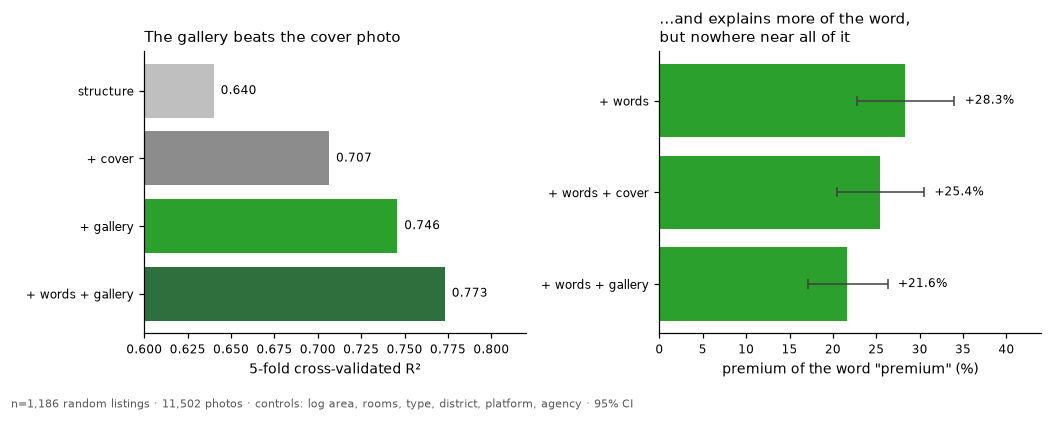

In [153]:
fig, (axL, axR) = plt.subplots(1, 2, figsize=(9.5, 3.6))

show = ladder[ladder.model.isin(["structure", "+ cover", "+ gallery", "+ words + gallery"])]
axL.barh(show.model[::-1], show["CV R²"][::-1],
         color=["0.75", "0.55", PALETTE["2"], "#2f6f3e"][::-1])
axL.set_xlim(0.60, 0.82)
axL.set_xlabel("5-fold cross-validated R²")
axL.set_title("The gallery beats the cover photo", loc="left")
for i, v in enumerate(show["CV R²"][::-1]):
    axL.text(v + 0.004, i, f"{v:.3f}", va="center", fontsize=8)

axR.barh(premium_ladder.model[::-1], premium_ladder["premium %"][::-1],
         xerr=np.vstack([(premium_ladder["premium %"] - premium_ladder.ci_lo)[::-1],
                         (premium_ladder.ci_hi - premium_ladder["premium %"])[::-1]]),
         color=PALETTE["2"], error_kw={"ecolor": "0.25", "elinewidth": 1, "capsize": 3})
axR.set_xlabel("premium of the word \"premium\" (%)")
axR.set_title("...and explains more of the word,\nbut nowhere near all of it", loc="left")
axR.set_xlim(0, 44)
# Label past the CI whisker, not past the bar, or the text lands on the error bar.
for i, (v, hi_i) in enumerate(zip(premium_ladder["premium %"][::-1], premium_ladder.ci_hi[::-1])):
    axR.text(hi_i + 1.2, i, f"{v:+.1f}%", va="center", fontsize=8)

fig.text(0.0, -0.04, f"n={len(gal):,} random listings · {len(V_gal):,} photos · "
                     "controls: log area, rooms, type, district, platform, agency · 95% CI",
         fontsize=7, color="0.35")
fig.tight_layout()
plt.show()

### 12.2 What the gallery adds

**The gallery clearly beats the cover, and it is not a parameter-count illusion.**
Cross-validated R²: structure **0.640** → +cover **0.707** → +gallery **0.746**. Adding
the cover photo *on top of* the gallery buys almost nothing (0.7474 vs 0.7458), which is
the tell — **the cover shot is a noisy sample of the gallery average**, carrying no
information of its own once the average is known.

**One variable does most of the work.** In the combined model, `modern_mean` is worth
**+10.9% per standard deviation** (t = +5.6) — roughly double what the cover's modern
axis was worth in §10, because averaging over nine photos cancels the noise in any one
shot. `bright_mean` adds +3.8%. Every `max` and `std` term is insignificant: **how good
the best room is, and how consistent the flat is, add nothing once the average is
known.** That is a genuinely useful negative result — it says a listing is priced on its
overall standard, not on its highlight or its worst room.

**And on the §9/§10 question.** The word "premium" goes **+28.3% → +25.4% (cover) →
+21.6% (gallery)** on this sample. The gallery explains about twice as much of the word
as the cover does — so §10.4's guess was right in direction. But **a quarter of the
adjective's value still survives nine photos of evidence.** Whatever "premium" is
tracking, it is not fully visible in the pictures.

*(The word's coefficient is larger here than §10's +19.6% because this is a 1,186-listing
random subsample with coarser district controls. Compare the three numbers to each
other, not to §10's.)*

### 12.3 If this gets taken further

The sample answers the question but does not produce a usable corpus-wide variable. What
would:

1. **Backfill gallery embeddings properly.** ~141k images for this date window at ~8 per
   listing. The existing `embedding-service/embed_job.py` already does cover photos in
   batches of 50 — extending it to loop `image_urls` and store a per-listing *mean*
   vector is a small change to a job that already exists, and a `gallery_embedding
   vector(512)` column alongside `image_embedding`. Storing the mean rather than every
   photo keeps it one row per listing and is, per §12.2, the only aggregate that pays.
2. **Skip `max` and `std`.** They cost 10 columns and earn nothing.
3. **The within-listing design from §9.3 is now within reach.** A listing that changes
   its photos between crawls, with an asking-price move, is the causal test — and
   gallery-mean is a far more stable subject for it than a swappable cover shot.

In [154]:
with open(REPORT, "a") as fh:
    fh.write("\n".join([
        "",
        "=" * 78,
        "SECTIONS 11-12 — boilerplate stripping, and the full photo gallery",
        "=" * 78,
        "",
        "11. BOILERPLATE STRIPPING (verbatim sentences in >=5 listings; 84.5% of text kept)",
        "",
        "  Cramer's V vs structure:  rooms 0.359 -> 0.212 | platform 0.425 -> 0.375",
        "                            agency 0.304 -> 0.271",
        "  BUT a classifier still recovers rooms from the stripped vectors at 77.9%",
        "  (raw: 78.1%) — the information was never removed, only de-emphasised, and",
        "  the agency clusters (APEX, ACE, 4Home) survive because identity lives in",
        "  writing STYLE, not repeated strings. Masking numbers made it worse.",
        f"  New thematic cluster (premium/finisaje/Herastrau, n=2,551): "
        f"{pct_ci(fit_cl, 'cl_' + sorted(set(clean_model.cluster_clean) - {base_clean})[0])[0]:+.1f}% "
        "(see notebook for all six)",
        "",
        f"12. GALLERY SAMPLE ({len(V_gal):,} photos, {gal_meta.url.nunique():,} listings)",
        "",
        ladder.to_string(index=False),
        "",
        "  The cover adds nothing once the gallery mean is known (CV 0.7474 vs 0.7458):",
        "  it is a noisy sample of the average. modern_mean is worth +10.9%/SD; every",
        "  'max' and 'std' term is insignificant — flats price on overall standard, not",
        "  on their best room.",
        "",
        premium_ladder.to_string(index=False),
        "",
        "  A quarter of the word 'premium' survives nine photos of evidence.",
        "",
    ]))
print("appended §11-12 to", REPORT)

appended §11-12 to /Users/alexandrus.home/Projects/Startup/Real-estate-parser/ad hoc analysis/cluster_report.txt


## What this run found

Numbers from the cells above, baseline = cluster 1 (2-room agency boilerplate),
n = 7,923, PCA 100 components (91% of variance), k = 6.

**The headline, stated carefully.** Listings in the premium-segment cluster rent for
**+13.1% [10.9, 15.4]** more than the baseline cluster after controlling for size,
rooms, property type, sector, platform and agency; **+10.1% [8.2, 12.1]** under district
fixed effects. The raw €/m² gap is +20.3%, so about a third of the naive number was
structure.

**§9 is what that headline actually means, and it is not what it looks like.** Racing
the individual phrases against each other:

* "una dintre cele mai bune zone" / "printre cele mai bune cartiere" — **+0.1%
  [−2.1, +2.4]**, a precisely estimated zero. The neighbourhood claim is worth nothing.
* "premium" **+19.5%**, "lux" **+12.9%** — and these co-occur with *finisaje* at 3.7×
  the corpus rate, i.e. they are describing fit-out, not location.
* placebos ("metrou", "mobilat") ≈ 0, so the model is not just rewarding enthusiastic copy.

With the phrases in the model the cluster's own coefficient falls from +13.1% to +6.2%.
So this is **not** "marketing inflates rent" — it is *expensive flats get described in
expensive vocabulary*, and the vocabulary is a proxy for quality the frame has no column
for. Correlational. The within-listing design that would settle it is described in §9.3.

**The result worth being careful about.** The single agency template (cluster 0, APEX,
n=297) prices **−8.3% [−11.0, −5.5]** below baseline controlled, against a raw gap of
only −2.6%. Controlling makes it *worse*, meaning that firm lists larger/better-located
stock at below-market rents for what it is. With one firm and 297 listings that is a
lead to check, not a finding to publish.

**The caveat that shapes everything.** §7 is the real headline for internal purposes:
raw embeddings of portal copy cluster on *room count and who wrote the ad*, not on
themes. Cluster 1 is 91% 2-room, cluster 4 is 63% 3-room, cluster 0 is one firm's
template. So the "renovated + parking" / "needs work + price flexible" kind of cluster
the original framing wanted is **not** what came out, and the hedonic controls are
load-bearing rather than decorative — without them most of these gaps are room count
in disguise.

**Before any of this leaves the building:**

* the frame is 7,950 of 19,371 listings, and the 10k description sample is
  URL-ordered rather than random (§ provenance) — the platform mix is not the
  population's;
* live listings only, so it says nothing about what actually *let* at these asks —
  these are asking rents, not transaction prices;
* k = 6 is the *lowest*-silhouette point of the sweep (0.074) and was chosen on
  legibility; the premium's sign and rough size should be re-checked at k = 5 and
  k = 8 before quoting a number publicly;
* cluster integer labels are not stable across re-runs — going from 50 to 100 PCs kept
  all six clusters but renumbered every one. Re-read `CLUSTER_LABELS` against §5 after
  any change to the seed, k, or `N_PCS`;
* cluster 2 was called "neighbourhood-quality language" until §9 showed the
  neighbourhood phrase is the one part of its vocabulary that pays nothing. It is now
  "premium-segment vocabulary". Names read off term lists are hypotheses — §9 is the
  test.

**§10 adds the evidence §9 was missing.** CLIP cover-photo axes show that listings
saying "premium" genuinely photograph as more luxurious (+0.54 SD) — the word is not
empty — but controlling for how the flat looks moves the coefficient only +19.6% →
+17.0%. The photo corroborates the adjective without accounting for it. Separately, one
cover image adds **+4.1 R² points** over structure alone on 17,693 listings and beats
the whole description: modern-looking **+5.6%**, bright **+3.7%**, luxury **+3.1%** per
standard deviation. That is the strongest standalone result in this notebook, and it
does not depend on the URL-ordered description sample.

**§11 tried the boilerplate fix, and it half-worked.** Stripping sentences that repeat
across ≥5 listings drops the clusters' coupling to room count (Cramér's V 0.359 → 0.212)
and surfaces one genuinely thematic cluster — *premium, finisaje, Herăstrău*, 2,551
listings, pricing at **+7.5% [6.1, 8.8]**. But a classifier still recovers room count
from the stripped vectors at 77.9% against 78.1% raw: the information was never removed,
only de-emphasised. The agency clusters survive outright, because identity lives in
writing style rather than repeated strings.

**§12 answered §10's open question with the rest of the gallery.** On 1,200 sampled
listings and 11,502 photos, cross-validated R² goes structure **0.640** → +cover
**0.707** → +gallery **0.746**, and the cover adds nothing once the gallery mean is known
— it is a noisy sample of the average. `modern_mean` alone is worth **+10.9% per SD**,
while every `max` and `std` term is insignificant: flats price on their overall standard,
not their best room. The word "premium" falls +28.3% → +25.4% (cover) → **+21.6%**
(gallery), so more photos do explain more of it — but a quarter of the adjective survives
nine photos of evidence.

**Next run:** backfill gallery-mean embeddings corpus-wide (§12.3 — a small extension to
`embed_job.py`, storing one mean vector per listing), and drop the `max`/`std` aggregates
that earned nothing. Removing authorial identity from the text would need an explicit
agency label to regress out, not a better string filter.